# Notes

# Setup

In [2]:
print('hello')

hello


In [60]:
%load_ext autoreload
%autoreload 2

import os
import datetime

import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox

import numpy as np
import rasterio

import config
import hatfield_funcs as hf
import hatfield_funcs.helpers as hfh

from pathlib import Path
import sys

project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))

from biofilm_data.io import (
    load_reflectance_spectra,
    load_contextual_data,
)

from my_extra_to_hatfield_funcs.io_funcs import (
    read_df_from_csv,
    write_df_to_csv,
    read_geojson,
    write_geojson,
)

from biofilm_data.plot import (
    plot_grouped_distribution,
    display_for_word,
    plot_contextual_scatter,
)

plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
if os.getenv("GA_STORAGE_ACCOUNT_NAME") is None:
    raise RuntimeError(
        "This notebook is configured for Azure cloud storage. "
        "Set GA_STORAGE_ACCOUNT_NAME before running it."
    )

hf.config.configure_azure()
hf.config.configure_data_root_path(config.CONTAINER_NAME)

# Tide and Time-reladed

## Compute Station Elevations

In [5]:
# GNSS Station Data
df_gnss = read_geojson(config.CONTAINER_FILE_PATHS["gnss_station_points_geojson"])
df_gnss = df_gnss[["round", "station_name", 'FIXDTTM', "geometry", "ELEVATION", 'corner']].rename(columns={"station_name": "station_id", "ELEVATION": "gnss_elevation"})
df_gnss["site"] = df_gnss["station_id"].str[0].map(lambda x: next((site for site in config.SITES if site.startswith(x.lower())), None))
df_gnss['date'] = pd.to_datetime(df_gnss["FIXDTTM"],errors="raise").dt.strftime("%Y-%m-%d")
df_gnss.drop(columns=['FIXDTTM'], inplace=True)
df_gnss["gnss_elevation_cd"] = df_gnss["gnss_elevation"] - config.CD_TO_OTHER_DATUM_CONVERSION_OFFSETS[config.GNSS_VERTICAL_DATUM]
df_gnss = df_gnss.set_index(["site", "round", "station_id", "corner"], inplace=False)
df_gnss_southwest = df_gnss.xs("SW", level="corner").copy(deep=True)
display(df_gnss_southwest.head())

geometry  \
site      round station_id                                            
brunswick 1     B24          POINT Z (490748.006 5433263.646 0.767)   
                B27         POINT Z (489976.691 5432602.785 -0.263)   
                B30          POINT Z (489836.101 5432131.465 0.317)   
                B29         POINT Z (489650.933 5432177.784 -0.384)   
                B28          POINT Z (489716.834 5432484.377 -0.48)   

                            gnss_elevation        date  gnss_elevation_cd  
site      round station_id                                                 
brunswick 1     B24                 0.7674  2026-05-05             3.7074  
                B27                -0.2628  2026-05-05             2.6772  
                B30                 0.3175  2026-05-05             3.2575  
                B29                -0.3839  2026-05-05             2.5561  
                B28                -0.4796  2026-05-05             2.4604

In [6]:
def sample_raster_at_points(
    points,
    raster_path,
    *,
    band=1,
):
    """Sample raster values at point locations.

    The points are temporarily reprojected to the raster CRS. Returned
    values use the same index and row order as the input GeoDataFrame.

    Parameters
    ----------
    points
        GeoDataFrame containing Point geometries and a defined CRS.

    raster_path
        Configured local or container-relative raster path.

    band
        One-based raster band number to sample.

    Returns
    -------
    values, raster_info
        values:
            Series indexed like ``points``.

        raster_info:
            Dictionary containing basic raster metadata.
    """

    if points.crs is None:
        raise ValueError(
            "The point GeoDataFrame has no CRS. Its CRS must be "
            "defined before sampling a raster."
        )

    if points.empty:
        return (
            pd.Series(
                index=points.index,
                dtype=float,
                name="raster_value",
            ),
            {},
        )

    full_raster_path = hfh.return_full_path(
        str(raster_path)
    )

    filesystem = hf.config.get_filesystem()

    if not filesystem.exists(full_raster_path):
        raise FileNotFoundError(
            f"Raster file not found: {raster_path}"
        )

    # Rasterio accepts an opened binary file-like object.
    with filesystem.open(full_raster_path, "rb") as raster_file:
        with rasterio.open(raster_file) as raster:
            if raster.crs is None:
                raise ValueError(
                    f"Raster has no defined CRS: {raster_path}"
                )

            if band < 1 or band > raster.count:
                raise ValueError(
                    f"Requested band {band}, but raster contains "
                    f"{raster.count} band(s)"
                )

            # Reproject a temporary copy; the original geometries are
            # left unchanged.
            sampling_points = points.to_crs(raster.crs)

            valid_geometry = (
                sampling_points.geometry.notna()
                & ~sampling_points.geometry.is_empty
                & sampling_points.geometry.geom_type.eq("Point")
            )

            values = np.full(
                len(sampling_points),
                np.nan,
                dtype=float,
            )

            valid_positions = np.flatnonzero(
                valid_geometry.to_numpy()
            )

            if len(valid_positions) > 0:
                valid_points = sampling_points.iloc[
                    valid_positions
                ]

                coordinates = [
                    (geometry.x, geometry.y)
                    for geometry in valid_points.geometry
                ]

                samples = list(
                    raster.sample(
                        coordinates,
                        indexes=band,
                        masked=True,
                    )
                )

                sampled_values = np.ma.vstack(samples)[:, 0]
                sampled_values = sampled_values.filled(
                    np.nan
                ).astype(float)

                if raster.nodata is not None:
                    sampled_values[
                        np.isclose(
                            sampled_values,
                            raster.nodata,
                            equal_nan=False,
                        )
                    ] = np.nan

                # Apply any scale and offset stored in the raster.
                scale = (
                    raster.scales[band - 1]
                    if raster.scales
                    else 1.0
                )
                offset = (
                    raster.offsets[band - 1]
                    if raster.offsets
                    else 0.0
                )

                finite = np.isfinite(sampled_values)
                sampled_values[finite] = (
                    sampled_values[finite] * scale
                    + offset
                )

                values[valid_positions] = sampled_values

            raster_info = {
                "path": str(raster_path),
                "crs": raster.crs,
                "bounds": raster.bounds,
                "resolution": raster.res,
                "nodata": raster.nodata,
                "band_count": raster.count,
                "dtype": raster.dtypes[band - 1],
                "scale": raster.scales[band - 1],
                "offset": raster.offsets[band - 1],
            }

    return (
        pd.Series(
            values,
            index=points.index,
            name="bathymetry_elevation",
        ),
        raster_info,
    )

In [7]:
df_gnss_southwest["bathymetry_elevation"] = np.nan

bathymetry_raster_info = {}

for site, raster_path in (
    config.CONTAINER_FILE_PATHS[
        "bathymetry_raster_per_site"
    ].items()
):
    site_mask = (
        df_gnss_southwest.index
        .get_level_values("site") == site
    )

    site_points = df_gnss_southwest.loc[
        site_mask
    ].copy()

    if site_points.empty:
        print(f"No GNSS points found for {site}")
        continue

    sampled_elevations, raster_info = (
        sample_raster_at_points(
            site_points,
            raster_path,
            band=1,
        )
    )

    # Use to_numpy() because site_mask preserves the same row order as
    # site_points.
    df_gnss_southwest.loc[
        site_mask,
        "bathymetry_elevation",
    ] = sampled_elevations.to_numpy()

    bathymetry_raster_info[site] = raster_info

    print(
        f"{site}: sampled "
        f"{sampled_elevations.notna().sum()} of "
        f"{len(sampled_elevations)} points"
    )

westham: sampled 60 of 60 points
brunswick: sampled 60 of 60 points


In [8]:
display(df_gnss_southwest.head())

geometry  \
site      round station_id                                            
brunswick 1     B24          POINT Z (490748.006 5433263.646 0.767)   
                B27         POINT Z (489976.691 5432602.785 -0.263)   
                B30          POINT Z (489836.101 5432131.465 0.317)   
                B29         POINT Z (489650.933 5432177.784 -0.384)   
                B28          POINT Z (489716.834 5432484.377 -0.48)   

                            gnss_elevation        date  gnss_elevation_cd  \
site      round station_id                                                  
brunswick 1     B24                 0.7674  2026-05-05             3.7074   
                B27                -0.2628  2026-05-05             2.6772   
                B30                 0.3175  2026-05-05             3.2575   
                B29                -0.3839  2026-05-05             2.5561   
                B28                -0.4796  2026-05-05             2.4604   

                            bathymetry_elevation  
site      round station_id                        
brunswick 1     B24                      3.59225  
                B27                      2.53775  
                B30                      3.11050  
                B29                      2.40650  
                B28                      2.25725

In [9]:
# plot_df = (
#     df_gnss_southwest
#     .reset_index()
#     .rename(columns={"site": "area"})
#     .dropna(
#         subset=[
#             "gnss_elevation_cd",
#             "bathymetry_elevation",
#         ]
#     )
# )

# fig, ax = plt.subplots(figsize=(7, 6))

# for area, group in plot_df.groupby("area"):
#     color = config.SITE_COLORS.get(area, "0.4")
#     label = config.SITE_LABELS.get(area, str(area))

#     ax.scatter(
#         group["gnss_elevation_cd"],
#         group["bathymetry_elevation"],
#         color=color,
#         edgecolor="black",
#         linewidth=0.4,
#         s=40,
#         label=label,
#         alpha=0.8,
#         zorder=2,
#     )

# ax.set(
#     xlabel=(
#         "GNSS elevation "
#         f"(converted to CD if {config.GNSS_VERTICAL_DATUM}) (m)"
#     ),
#     ylabel="Bathymetry elevation (m)",
#     title="GNSS versus bathymetry elevation",
# )

# # Determine a common range using both variables
# reference_min = min(
#     plot_df["gnss_elevation_cd"].min(),
#     plot_df["bathymetry_elevation"].min(),
# )

# reference_max = max(
#     plot_df["gnss_elevation_cd"].max(),
#     plot_df["bathymetry_elevation"].max(),
# )

# # Add a 1:1 reference line
# ax.plot(
#     [reference_min, reference_max],
#     [reference_min, reference_max],
#     color="gray",
#     linestyle="--",
#     linewidth=1,
#     label="1:1 reference",
#     zorder=1,
# )

# ax.legend(
#     # title="Area",
#     frameon=True,
# )

# ax.grid(
#     axis="both",
#     linestyle=":",
#     linewidth=0.8,
#     alpha=0.4,
# )

# plt.tight_layout()
# plt.show()

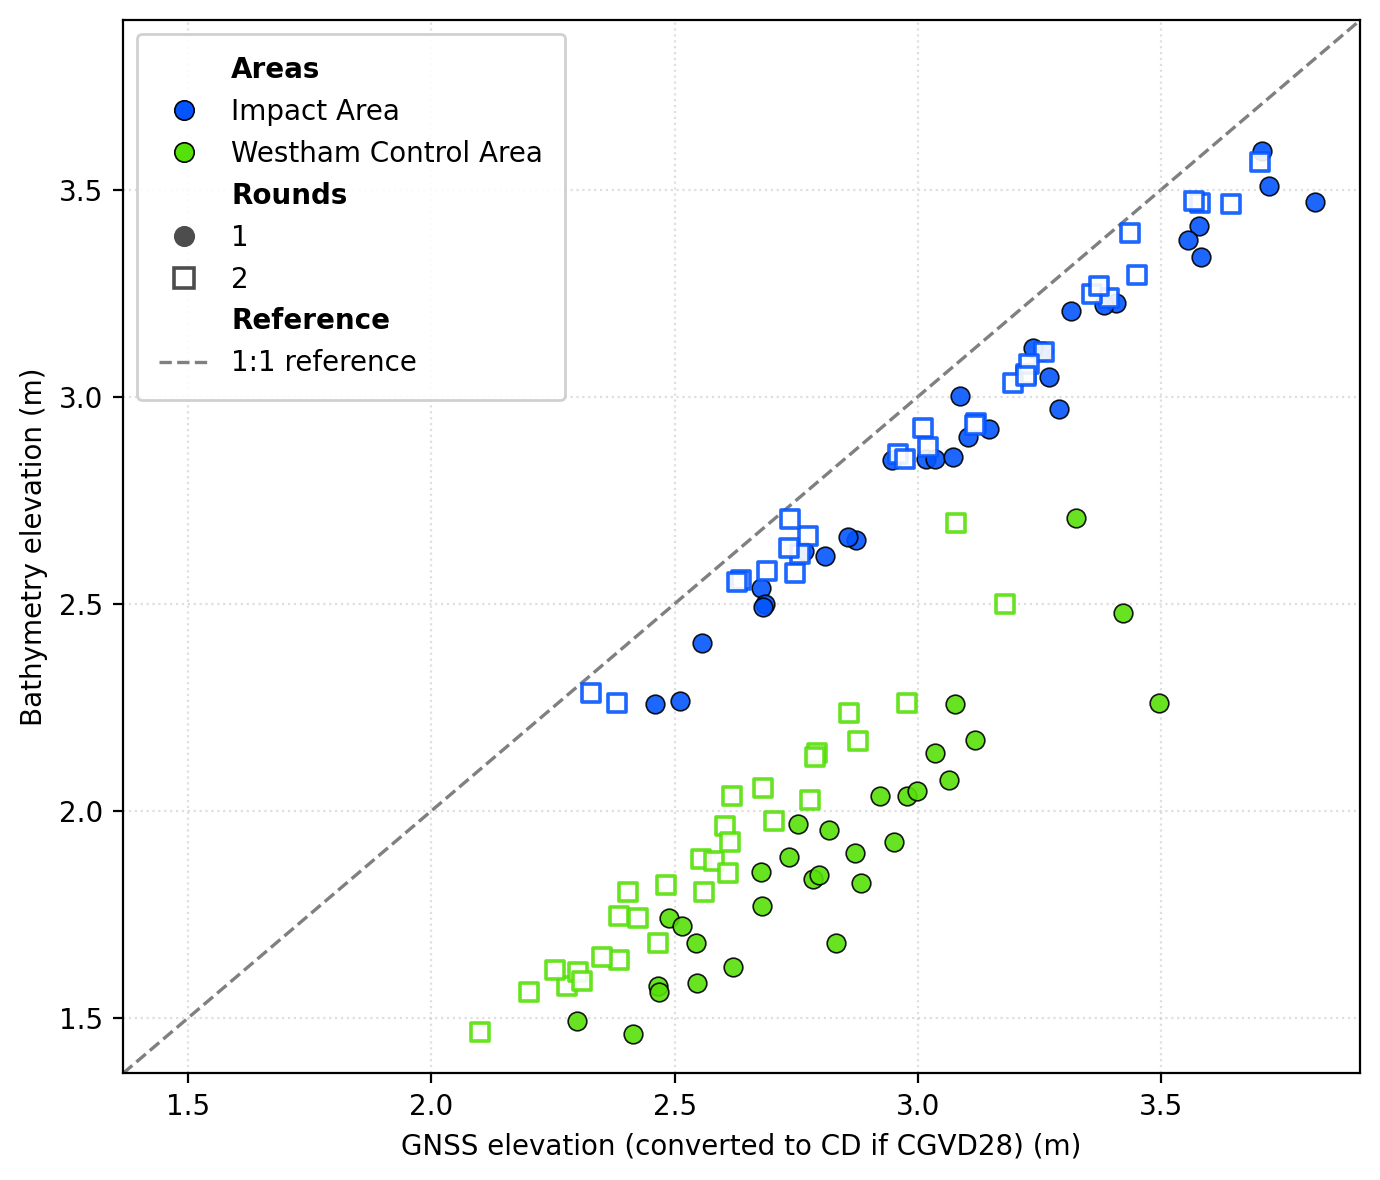

In [10]:

plot_df = (
    df_gnss_southwest
    .reset_index()
    .rename(columns={"site": "area"})
    .dropna(
        subset=[
            "area",
            "round",
            "gnss_elevation_cd",
            "bathymetry_elevation",
        ]
    )
    .copy()
)

# Areas in the order defined by SITE_COLORS, when possible
observed_areas = list(
    plot_df["area"].unique()
)

areas = [
    area
    for area in config.SITE_COLORS
    if area in observed_areas
]

areas += [
    area
    for area in observed_areas
    if area not in areas
]

rounds = sorted(
    plot_df["round"].unique(),
    key=str,
)

# Use the same round markers as the NDVI/spectral-angle plot
available_markers = [
    "o",
    "s",
    "^",
    "D",
    "P",
    "v",
    "X",
    "<",
    ">",
]

round_markers = {
    round_value: available_markers[
        i % len(available_markers)
    ]
    for i, round_value in enumerate(rounds)
}

# Alternate filled and open markers among rounds
round_filled = {
    round_value: i % 2 == 0
    for i, round_value in enumerate(rounds)
}

fig, ax = plt.subplots(figsize=(7, 6))

# Plot each area and round separately
for (area, round_value), group in plot_df.groupby(
    ["area", "round"],
    sort=False,
):
    color = config.SITE_COLORS.get(
        area,
        "0.4",
    )

    marker = round_markers[round_value]
    filled = round_filled[round_value]

    ax.scatter(
        group["gnss_elevation_cd"],
        group["bathymetry_elevation"],
        marker=marker,
        s=45,
        facecolor=(
            color
            if filled
            else "white"
        ),
        edgecolor=(
            "black"
            if filled
            else color
        ),
        linewidth=(
            0.6
            if filled
            else 1.3
        ),
        alpha=0.9,
        zorder=2,
    )

ax.set(
    xlabel=(
        "GNSS elevation "
        f"(converted to CD if {config.GNSS_VERTICAL_DATUM}) (m)"
    ),
    ylabel="Bathymetry elevation (m)",
    # title="GNSS versus bathymetry elevation",
)

# Determine a common range using both variables
reference_min = min(
    plot_df["gnss_elevation_cd"].min(),
    plot_df["bathymetry_elevation"].min(),
)

reference_max = max(
    plot_df["gnss_elevation_cd"].max(),
    plot_df["bathymetry_elevation"].max(),
)

reference_range = reference_max - reference_min

if reference_range <= 0:
    reference_range = 1

reference_padding = 0.04 * reference_range

axis_min = reference_min - reference_padding
axis_max = reference_max + reference_padding

# Add a 1:1 reference line
ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    zorder=1,
)

# Use the same limits on both axes so the 1:1 relationship is
# represented consistently.
ax.set_xlim(axis_min, axis_max)
ax.set_ylim(axis_min, axis_max)

# --------------------------------------------------------------
# Combined legend
# --------------------------------------------------------------

area_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=config.SITE_COLORS.get(
            area,
            "0.4",
        ),
        markeredgecolor="black",
        markeredgewidth=0.6,
        markersize=7,
        label=config.SITE_LABELS.get(
            area,
            str(area),
        ),
    )
    for area in areas
]

round_handles = [
    Line2D(
        [0],
        [0],
        marker=round_markers[round_value],
        linestyle="none",
        markerfacecolor=(
            "0.3"
            if round_filled[round_value]
            else "white"
        ),
        markeredgecolor="0.3",
        markeredgewidth=(
            0.6
            if round_filled[round_value]
            else 1.3
        ),
        markersize=7,
        label=str(round_value),
    )
    for round_value in rounds
]

reference_handle = Line2D(
    [0],
    [0],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="1:1 reference",
)


def section_handle(label):
    return Line2D(
        [],
        [],
        linestyle="none",
        marker="",
        color="none",
        label=label,
    )


combined_handles = [
    section_handle("Areas"),
    *area_handles,
    section_handle("Rounds"),
    *round_handles,
    section_handle("Reference"),
    reference_handle,
]

combined_legend = ax.legend(
    handles=combined_handles,
    loc="best",
    frameon=True,
    framealpha=0.9,
    borderpad=0.8,
    labelspacing=0.5,
    handlelength=1.8,
)

# Make legend section headings bold
for legend_text in combined_legend.get_texts():
    if legend_text.get_text() in {
        "Areas",
        "Rounds",
        "Reference",
    }:
        legend_text.set_fontweight("bold")

ax.grid(
    visible=True,
    which="major",
    axis="both",
    linestyle=":",
    linewidth=0.8,
    alpha=0.4,
)

plt.tight_layout()
plt.show()

In [11]:
# Compute mean bias for Brunswick between GNSS elevations and bathynetry elevations
gnss_bias = df_gnss_southwest["gnss_elevation_cd"] - df_gnss_southwest["bathymetry_elevation"]
mean_gnss_bias_brunswick = gnss_bias.xs("brunswick", level="site").mean()
print(f'Mean GNSS bias for Brunswick: {mean_gnss_bias_brunswick*100:+.1f} cm')

mean_gnss_bias_brunswick_round_1 = gnss_bias.xs(("brunswick", 1), level=("site", "round")).mean()
print(f'Mean GNSS bias for Brunswick round 1: {mean_gnss_bias_brunswick_round_1*100:+.1f} cm')

mean_gnss_bias_brunswick_round_2 = gnss_bias.xs(("brunswick", 2), level=("site", "round")).mean()
print(f'Mean GNSS bias for Brunswick round 2: {mean_gnss_bias_brunswick_round_2*100:+.1f} cm')

# Same for Westham:
mean_gnss_bias_westham_round_1 = gnss_bias.xs(("westham", 1), level=("site", "round")).mean()
print(f'Mean GNSS bias for Westham round 1: {mean_gnss_bias_westham_round_1*100:+.1f} cm')

mean_gnss_bias_westham_round_2 = gnss_bias.xs(("westham", 2), level=("site", "round")).mean()
print(f'Mean GNSS bias for Westham round 2: {mean_gnss_bias_westham_round_2*100:+.1f} cm')

# Correction to apply to Westham round 2 is the same as Brunswick round 1, same person = Jason
correction_to_gnss_westham_round_2 = -mean_gnss_bias_brunswick_round_1
print(f'Correction to apply to Westham round 2: {correction_to_gnss_westham_round_2*100:+.1f} cm')

# Correction to apply to Westham round 1 is to make it consistent between rounds
difference_bias_westham_round2_vs_round1 = mean_gnss_bias_westham_round_2 - mean_gnss_bias_westham_round_1
correction_to_gnss_westham_round_1 = correction_to_gnss_westham_round_2 + difference_bias_westham_round2_vs_round1
print(f'Correction to apply to Westham round 1: {correction_to_gnss_westham_round_1*100:+.1f} cm')

Mean GNSS bias for Brunswick: +15.4 cm
Mean GNSS bias for Brunswick round 1: +18.5 cm
Mean GNSS bias for Brunswick round 2: +12.3 cm
Mean GNSS bias for Westham round 1: +91.6 cm
Mean GNSS bias for Westham round 2: +67.2 cm
Correction to apply to Westham round 2: -18.5 cm
Correction to apply to Westham round 1: -42.9 cm


In [12]:
# Use bathymetry elevations for elevations in Brunswick
brunswick_mask = df_gnss_southwest.index.get_level_values("site") == "brunswick"
df_gnss_southwest.loc[brunswick_mask, "elevation"] = df_gnss_southwest.loc[brunswick_mask, "bathymetry_elevation"]

# Apply corrections to Westham rounds based on computed correction offsets
westham_mask_1 = (df_gnss_southwest.index.get_level_values("site") == "westham") & (df_gnss_southwest.index.get_level_values("round") == 1)
df_gnss_southwest.loc[westham_mask_1, "elevation"] = df_gnss_southwest.loc[westham_mask_1, "gnss_elevation_cd"] + correction_to_gnss_westham_round_1

westham_mask_2 = (df_gnss_southwest.index.get_level_values("site") == "westham") & (df_gnss_southwest.index.get_level_values("round") == 2)
df_gnss_southwest.loc[westham_mask_2, "elevation"] = df_gnss_southwest.loc[westham_mask_2, "gnss_elevation_cd"] + correction_to_gnss_westham_round_2

display(df_gnss_southwest.head())

geometry  \
site      round station_id                                            
brunswick 1     B24          POINT Z (490748.006 5433263.646 0.767)   
                B27         POINT Z (489976.691 5432602.785 -0.263)   
                B30          POINT Z (489836.101 5432131.465 0.317)   
                B29         POINT Z (489650.933 5432177.784 -0.384)   
                B28          POINT Z (489716.834 5432484.377 -0.48)   

                            gnss_elevation        date  gnss_elevation_cd  \
site      round station_id                                                  
brunswick 1     B24                 0.7674  2026-05-05             3.7074   
                B27                -0.2628  2026-05-05             2.6772   
                B30                 0.3175  2026-05-05             3.2575   
                B29                -0.3839  2026-05-05             2.5561   
                B28                -0.4796  2026-05-05             2.4604   

                            bathymetry_elevation  elevation  
site      round station_id                                   
brunswick 1     B24                      3.59225    3.59225  
                B27                      2.53775    2.53775  
                B30                      3.11050    3.11050  
                B29                      2.40650    2.40650  
                B28                      2.25725    2.25725

In [13]:
# # Save geometry and elevation to a new geojson file

# write_geojson(
#     df_gnss_southwest[["geometry", "date", "elevation"]],
#     config.CONTAINER_FILE_PATHS["station_elevations_geojson"],
#     index=True,
# )

# # To read it back:
# # read_geojson(config.CONTAINER_FILE_PATHS["station_elevations_geojson"]).set_index(["site", "round", "station_id"]).sort_index()

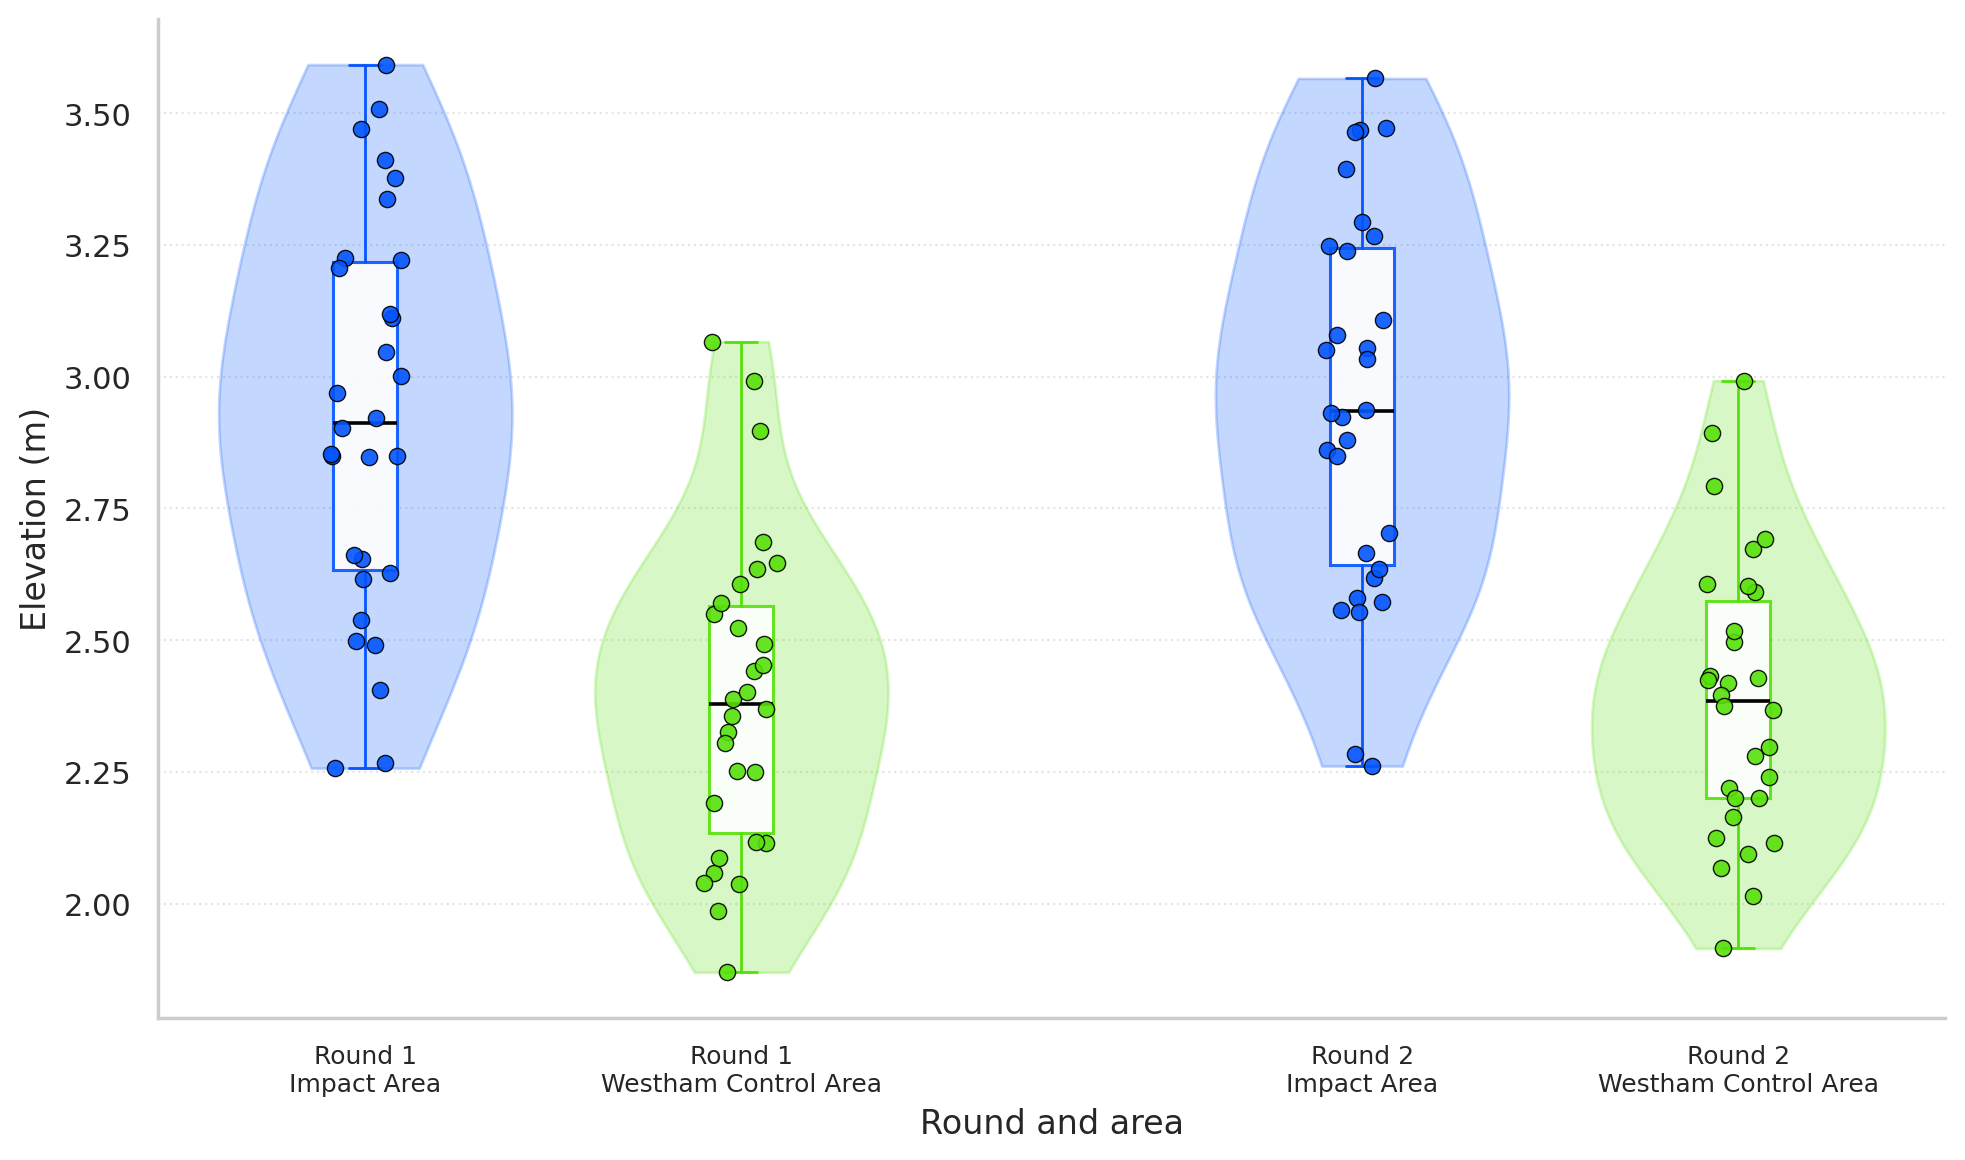

In [14]:
fig, ax, plot_df = plot_grouped_distribution(
    dataframe=df_gnss_southwest,
    value_column="elevation",
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    group_by="round",
    ylabel="Elevation (m)",
    # y_min=0,
    figsize=(10, 6),
)

plt.show()

## Process Tide Data

In [15]:
# Find and load the files

dir_path = config.CONTAINER_DIR_PATHS["raw_tide_data"]

filesystem = hf.config.get_filesystem()
full_dir_path = hfh.return_full_path(str(dir_path)).rstrip("/")

matched_files = sorted(
    file_path
    for file_path in filesystem.glob(f"{full_dir_path}/*")
    if str(file_path).lower().endswith(".csv")
)

if not matched_files:
    raise FileNotFoundError(f"No CSV files found in {dir_path}")

file_paths = []

for file_path in matched_files:
    filename = str(file_path).replace("\\", "/").rsplit("/", 1)[-1]

    relative_path = f"{str(dir_path).rstrip('/')}/{filename}"

    file_paths.append(relative_path)

tide_frames = []

for source_order, file_path in enumerate(file_paths):
    filename = str(file_path).replace("\\", "/").rsplit("/", 1)[-1]

    dataframe = read_df_from_csv(
        file_path,
        index_col=None,
        on_bad_lines="warn",
    )

    required_columns = {
        "Date",
        "predictions (m)",
    }

    missing_columns = required_columns.difference(dataframe.columns)

    if missing_columns:
        raise ValueError(f"Missing columns in {filename}: {sorted(missing_columns)}")

    dataframe = dataframe[["Date", "predictions (m)"]].copy()

    dataframe["source_file"] = filename
    dataframe["_source_order"] = source_order

    tide_frames.append(dataframe)

/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/src/my_extra_to_hatfield_funcs/io_funcs.py:51: ParserWarning: Skipping line 10082: expected 2 fields, saw 3

  df = pd.read_csv(f, index_col=index_col, **kwargs)
/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/src/my_extra_to_hatfield_funcs/io_funcs.py:51: ParserWarning: Skipping line 10082: expected 2 fields, saw 3

  df = pd.read_csv(f, index_col=index_col, **kwargs)
/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/src/my_extra_to_hatfield_funcs/io_funcs.py:51: ParserWarning: Skipping line 10082: expected 2 fields, saw 3

  df = pd.read_csv(f, index_col=index_col, **kwargs)
/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/src/my_extra_to_hatfield_funcs/io_funcs.py:51: ParserWarning: Skipping line 10082: expected 2 fields, saw 3

  df = pd.read_csv(f, index_col=index_col, **kwargs)
/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/src/my_

In [16]:
# Combine all tide frames into a single DataFrame
tide_raw = pd.concat(
    tide_frames,
    ignore_index=True,
)


In [17]:
# Parse the PDT/PST timestamps and replace the timezone abbreviations with their UTC offsets
# Convert height values

date_text = tide_raw["Date"].astype("string").str.strip()

unknown_timezone = ~date_text.str.endswith(
    (" PDT", " PST"),
    na=False,
)

if unknown_timezone.any():
    unknown_values = date_text.loc[unknown_timezone].drop_duplicates().tolist()

    raise ValueError(
        f"Some tide timestamps do not end in PDT or PST: {unknown_values[:10]}"
    )

date_with_offset = date_text.str.replace(
    r"\s+PDT$",
    " -0700",
    regex=True,
).str.replace(
    r"\s+PST$",
    " -0800",
    regex=True,
)

tide_raw["datetime_utc"] = pd.to_datetime(
    date_with_offset,
    format="%Y-%m-%d %H:%M %z",
    errors="coerce",
    utc=True,
)

tide_raw["datetime_local"] = tide_raw["datetime_utc"].dt.tz_convert("America/Vancouver")

invalid_dates = tide_raw.loc[tide_raw["datetime_utc"].isna()]

if not invalid_dates.empty:
    display(invalid_dates.head())

    raise ValueError(f"{len(invalid_dates)} tide records have invalid dates")

tide_raw["predictions (m)"] = pd.to_numeric(
    tide_raw["predictions (m)"],
    errors="coerce",
)

invalid_predictions = tide_raw.loc[tide_raw["predictions (m)"].isna()]

if not invalid_predictions.empty:
    display(invalid_predictions.head())

    raise ValueError(
        f"{len(invalid_predictions)} tide records have invalid predictions"
    )

In [18]:
# Inspect overlaps

overlapping_records = tide_raw.loc[
    tide_raw.duplicated(
        subset="datetime_utc",
        keep=False,
    )
].sort_values(["datetime_utc", "_source_order"])

print(f"{len(overlapping_records):,} records occur at overlapping timestamps.")

display(overlapping_records.head(20))

overlap_summary = overlapping_records.groupby("datetime_utc").agg(
    record_count=("predictions (m)", "size"),
    source_file_count=("source_file", "nunique"),
    minimum_prediction=("predictions (m)", "min"),
    maximum_prediction=("predictions (m)", "max"),
)

overlap_summary["prediction_difference"] = (
    overlap_summary["maximum_prediction"] - overlap_summary["minimum_prediction"]
)

display(overlap_summary.head(20))

28,796 records occur at overlapping timestamps.


,Date,predictions (m),source_file,_source_order,datetime_utc,datetime_local
7199,2026-05-04 17:50 PDT,2.733,predictions_07592_Roberts Bank_2026-04-30.csv,0,2026-05-05 00:50:00+00:00,2026-05-04 17:50:00-07:00
10080,2026-05-04 17:50 PDT,2.733,predictions_07592_Roberts Bank_2026-05-05.csv,1,2026-05-05 00:50:00+00:00,2026-05-04 17:50:00-07:00
7200,2026-05-04 17:51 PDT,2.744,predictions_07592_Roberts Bank_2026-04-30.csv,0,2026-05-05 00:51:00+00:00,2026-05-04 17:51:00-07:00
10081,2026-05-04 17:51 PDT,2.744,predictions_07592_Roberts Bank_2026-05-05.csv,1,2026-05-05 00:51:00+00:00,2026-05-04 17:51:00-07:00
7201,2026-05-04 17:52 PDT,2.755,predictions_07592_Roberts Bank_2026-04-30.csv,0,2026-05-05 00:52:00+00:00,2026-05-04 17:52:00-07:00
10082,2026-05-04 17:52 PDT,2.755,predictions_07592_Roberts Bank_2026-05-05.csv,1,2026-05-05 00:52:00+00:00,2026-05-04 17:52:00-07:00
7202,2026-05-04 17:53 PDT,2.766,predictions_07592_Roberts Bank_2026-04-30.csv,0,2026-05-05 00:53:00+00:00,2026-05-04 17:53:00-07:00
10083,2026-05-04 17:53 PDT,2.766,predictions_07592_Roberts Bank_2026-05-05.csv,1,2026-05-05 00:53:00+00:00,2026-05-04 17:53:00-07:00
7203,2026-05-04 17:54 PDT,2.777,predictions_07592_Roberts Bank_2026-04-30.csv,0,2026-05-05 00:54:00+00:00,2026-05-04 17:54:00-07:00
10084,2026-05-04 17:54 PDT,2.777,predictions_07592_Roberts Bank_2026-05-05.csv,1,2026-05-05 00:54:00+00:00,2026-05-04 17:54:00-07:00


,record_count,source_file_count,minimum_prediction,maximum_prediction,prediction_difference
datetime_utc,,,,,
2026-05-05 00:50:00+00:00,2,2,2.733,2.733,0.0
2026-05-05 00:51:00+00:00,2,2,2.744,2.744,0.0
2026-05-05 00:52:00+00:00,2,2,2.755,2.755,0.0
2026-05-05 00:53:00+00:00,2,2,2.766,2.766,0.0
2026-05-05 00:54:00+00:00,2,2,2.777,2.777,0.0
2026-05-05 00:55:00+00:00,2,2,2.788,2.788,0.0
2026-05-05 00:56:00+00:00,2,2,2.799,2.799,0.0
2026-05-05 00:57:00+00:00,2,2,2.810,2.810,0.0
2026-05-05 00:58:00+00:00,2,2,2.821,2.821,0.0


In [19]:
# Detect conflicting predictions

prediction_tolerance_m = 0.0005

conflicting_overlaps = overlap_summary.loc[
    overlap_summary["prediction_difference"] > prediction_tolerance_m
]

print(
    f"{len(conflicting_overlaps):,} overlapping timestamps "
    "contain conflicting predictions."
)

if not conflicting_overlaps.empty:
    conflicting_records = overlapping_records.loc[
        overlapping_records["datetime_utc"].isin(conflicting_overlaps.index)
    ]

    display(conflicting_records.head(50))

if not conflicting_overlaps.empty:
    raise ValueError(
        "Overlapping tide files contain conflicting predictions. "
        "Inspect conflicting_records before continuing."
    )

0 overlapping timestamps contain conflicting predictions.


In [20]:
# Create the combined time series

tide_df = (
    tide_raw.sort_values(["datetime_utc", "_source_order"])
    .drop_duplicates(
        subset="datetime_utc",
        keep="first",
    )
    .sort_values("datetime_utc")
    .drop(columns="_source_order")
    .reset_index(drop=True)
)

tide_df = tide_df.rename(
    columns={
        "predictions (m)": "predicted_tide_m",
    }
)

In [21]:
# Check for gaps

tide_df["time_step"] = tide_df["datetime_utc"].diff()

gaps = tide_df.loc[tide_df["time_step"] > pd.Timedelta(minutes=1)]

print(f"Found {len(gaps):,} gaps longer than one minute.")

display(
    gaps[
        [
            "datetime_local",
            "time_step",
            "source_file",
        ]
    ].head(20)
)

tide_df = tide_df.drop(columns="time_step")

tide_df = (
    tide_df.set_index("datetime_utc")
    .sort_index()
    .filter(["predicted_tide_m", "datetime_local"])
)

Found 0 gaps longer than one minute.


,datetime_local,time_step,source_file


<Axes: xlabel='datetime_utc'>

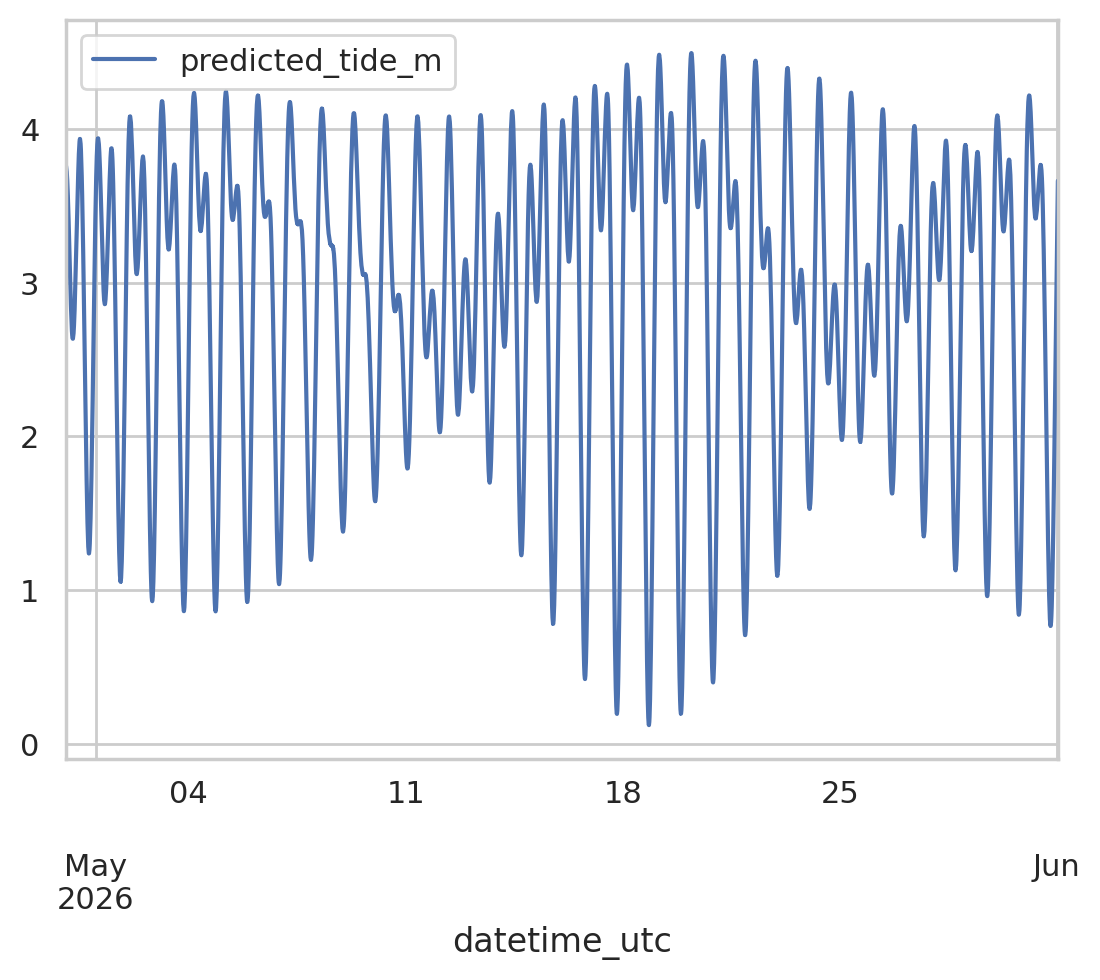

In [22]:
tide_df.plot(y="predicted_tide_m")


In [23]:
# Save cleaned tide data
write_df_to_csv(tide_df,config.CONTAINER_FILE_PATHS["processed_tide_data_csv"], index=True)

DataFrame saved to wesa-fup-restricted-027817p/data/processed/contextual/processed_tide_data.csv


## Compute Emergence Times

In [24]:
# Prepare the predicted tide series in local time.

tide_times = pd.to_datetime(
    tide_df["datetime_local"],
    errors="coerce",
)

tide_levels = pd.to_numeric(
    tide_df["predicted_tide_m"],
    errors="coerce",
)

valid_tide_rows = (
    tide_times.notna()
    & tide_levels.notna()
)

tide = pd.Series(
    tide_levels.loc[valid_tide_rows].to_numpy(),
    index=pd.DatetimeIndex(
        tide_times.loc[valid_tide_rows]
    ),
    name="predicted_tide_m",
)

# Average any remaining duplicate timestamps and sort.
tide = (
    tide
    .groupby(level=0)
    .mean()
    .sort_index()
)

# Parse station dates without changing the original column.
station_dates = pd.to_datetime(
    df_gnss_southwest["date"],
    errors="coerce",
).dt.date

emergence_rows = []

for date in sorted(station_dates.dropna().unique()):
    station_subset = df_gnss_southwest.loc[
        station_dates == date
    ]

    start_date = pd.Timestamp(date)

    if tide.index.tz is not None:
        start_date = start_date.tz_localize(
            tide.index.tz
        )

    end_date = start_date + pd.Timedelta(days=1)

    # Identify the lowest predicted tide on the station date.
    tide_day = tide.loc[
        (tide.index >= start_date)
        & (tide.index < end_date)
    ]

    if tide_day.empty:
        for station_index, station in station_subset.iterrows():
            station_info = dict(
                zip(
                    df_gnss_southwest.index.names,
                    station_index,
                )
            )

            emergence_rows.append(
                {
                    **station_info,
                    'geometry': station["geometry"],
                    "date": date,
                    "elevation": station["elevation"],
                    "low_tide_time": pd.NaT,
                    "low_tide_level": np.nan,
                    "emergence_time": pd.NaT,
                    "submergence_time": pd.NaT,
                    "exposure_duration_hours": np.nan,
                    "status": "no_tide_data",
                }
            )

        continue

    low_tide_time = tide_day.idxmin()
    low_tide_level = tide_day.min()

    # Include the surrounding tidal cycle so crossings can occur on
    # the preceding or following date.
    tide_window = tide.loc[
        low_tide_time - pd.Timedelta(hours=12):
        low_tide_time + pd.Timedelta(hours=12)
    ]

    before_low_tide = tide_window.loc[:low_tide_time]
    after_low_tide = tide_window.loc[low_tide_time:]

    before_levels = before_low_tide.to_numpy(dtype=float)
    after_levels = after_low_tide.to_numpy(dtype=float)

    for station_index, station in station_subset.iterrows():
        station_info = dict(
            zip(
                df_gnss_southwest.index.names,
                station_index,
            )
        )

        elevation = pd.to_numeric(
            station["elevation"],
            errors="coerce",
        )

        result = {
            **station_info,
            "date": date,
            'geometry': station["geometry"],
            "elevation": elevation,
            "low_tide_time": low_tide_time,
            "low_tide_level": low_tide_level,
            "emergence_time": pd.NaT,
            "submergence_time": pd.NaT,
            "exposure_duration_hours": np.nan,
            "status": None,
        }

        if pd.isna(elevation):
            result["status"] = "missing_elevation"
            emergence_rows.append(result)
            continue

        # Tide remains above the station even at the lowest tide.
        if low_tide_level >= elevation:
            result["status"] = "never_emerged"
            emergence_rows.append(result)
            continue

        # -----------------------------------------------------------
        # Emergence: final submerged-to-exposed crossing before low
        # tide.
        #
        # Submerged: tide > elevation
        # Exposed:   tide <= elevation
        # -----------------------------------------------------------

        falling_crossings = np.flatnonzero(
            (before_levels[:-1] > elevation)
            & (before_levels[1:] <= elevation)
        )

        if len(falling_crossings) == 0:
            result["status"] = "no_emergence_crossing"
            emergence_rows.append(result)
            continue

        position = falling_crossings[-1]

        time_before = before_low_tide.index[position]
        time_after = before_low_tide.index[position + 1]

        level_before = before_levels[position]
        level_after = before_levels[position + 1]

        fraction = (
            (elevation - level_before)
            / (level_after - level_before)
        )

        emergence_time = (
            time_before
            + fraction * (time_after - time_before)
        )

        # -----------------------------------------------------------
        # Submergence: first exposed-to-submerged crossing after low
        # tide.
        # -----------------------------------------------------------

        rising_crossings = np.flatnonzero(
            (after_levels[:-1] <= elevation)
            & (after_levels[1:] > elevation)
        )

        if len(rising_crossings) == 0:
            result["emergence_time"] = emergence_time
            result["status"] = "no_submergence_crossing"
            emergence_rows.append(result)
            continue

        position = rising_crossings[0]

        time_before = after_low_tide.index[position]
        time_after = after_low_tide.index[position + 1]

        level_before = after_levels[position]
        level_after = after_levels[position + 1]

        fraction = (
            (elevation - level_before)
            / (level_after - level_before)
        )

        submergence_time = (
            time_before
            + fraction * (time_after - time_before)
        )

        result["emergence_time"] = emergence_time
        result["submergence_time"] = submergence_time
        result["exposure_duration_hours"] = (
            submergence_time
            - emergence_time
        ).total_seconds() / 3600
        result["status"] = "ok"

        emergence_rows.append(result)

df_emergence_times = gpd.GeoDataFrame(
    emergence_rows,
    geometry="geometry",
    crs=df_gnss_southwest.crs,
)

df_emergence_times = (
    df_emergence_times
    .set_index(
        [
            "site",
            "round",
            "station_id",
        ]
    )
    .sort_index()
)

display(df_emergence_times.head())

display(
    df_emergence_times["status"]
    .value_counts(dropna=False)
)

date  \
site      round station_id               
brunswick 1     B1          2026-05-03   
                B10         2026-05-01   
                B11         2026-05-01   
                B12         2026-05-01   
                B13         2026-05-01   

                                                          geometry  elevation  \
site      round station_id                                                      
brunswick 1     B1           POINT Z (488833.82 5434224.912 0.875)    3.46975   
                B10         POINT Z (488875.848 5433865.401 0.616)    3.37800   
                B11         POINT Z (489056.793 5433627.776 0.376)    3.20575   
                B12          POINT Z (488897.659 5433305.857 0.33)    3.04725   
                B13         POINT Z (488555.946 5433166.387 0.133)    2.85350   

                                       low_tide_time  low_tide_level  \
site      round station_id                                             
brunswick 1     B1         2026-05-03 13:10:00-07:00           0.862   
                B10        2026-05-01 12:11:00-07:00           1.053   
                B11        2026-05-01 12:11:00-07:00           1.053   
                B12        2026-05-01 12:11:00-07:00           1.053   
                B13        2026-05-01 12:11:00-07:00           1.053   

                                                emergence_time  \
site      round station_id                                       
brunswick 1     B1         2026-05-03 07:28:42.500724792-07:00   
                B10        2026-05-01 07:07:44.999842643-07:00   
                B11        2026-05-01 07:28:48.333409627-07:00   
                B12        2026-05-01 07:46:44.999783833-07:00   
                B13        2026-05-01 08:07:33.000663757-07:00   

                                              submergence_time  \
site      round station_id                                       
brunswick 1     B1         2026-05-03 18:23:51.666183471-07:00   
                B10        2026-05-01 17:06:06.666806538-07:00   
                B11        2026-05-01 16:48:04.499931335-07:00   
                B12        2026-05-01 16:32:25.500194549-07:00   
                B13        2026-05-01 16:13:57.272123856-07:00   

                            exposure_duration_hours status  
site      round station_id                                  
brunswick 1     B1                        10.919213     ok  
                B10                        9.972685     ok  
                B11                        9.321157     ok  
                B12                        8.761250     ok  
                B13                        8.106742     ok

status
ok    120
Name: count, dtype: int64

In [25]:


# def _add_non_overlapping_station_annotations(
#     ax,
#     station_annotations,
#     *,
#     minimum_horizontal_offset=8,
#     maximum_horizontal_offset=140,
#     horizontal_step=10,
#     vertical_offsets=(0, 4, -4, 8, -8, 12, -12, 18, -18),
#     label_padding_points=2,
# ):
#     """
#     Add station labels while prioritizing horizontal movement.

#     The function first tries to place each label at the same vertical
#     level as its station. Small vertical offsets are only considered
#     if horizontal movement alone cannot prevent overlap.
#     """

#     if not station_annotations:
#         return []

#     fig = ax.figure

#     # Render the figure so that text bounding boxes can be calculated.
#     fig.canvas.draw()
#     renderer = fig.canvas.get_renderer()

#     horizontal_distances = np.arange(
#         minimum_horizontal_offset,
#         maximum_horizontal_offset + horizontal_step,
#         horizontal_step,
#     )

#     padding_pixels = (
#         label_padding_points
#         * fig.dpi
#         / 72
#     )

#     figure_bbox = fig.bbox
#     placed_bboxes = []
#     annotation_artists = []

#     # Sort annotations for consistent results.
#     sorted_annotations = sorted(
#         station_annotations,
#         key=lambda item: (
#             item["side"],
#             item["elevation"],
#             str(item["station_id"]),
#         ),
#     )

#     for item in sorted_annotations:
#         if item["side"] == "emergence":
#             horizontal_offsets = -horizontal_distances
#             horizontal_alignment = "right"
#         else:
#             horizontal_offsets = horizontal_distances
#             horizontal_alignment = "left"

#         # All horizontal positions at vertical offset zero are tested
#         # first. Vertical movement is only considered afterward.
#         candidate_positions = [
#             (horizontal_offset, vertical_offset)
#             for vertical_offset in vertical_offsets
#             for horizontal_offset in horizontal_offsets
#         ]

#         first_position = candidate_positions[0]

#         annotation = ax.annotate(
#             str(item["station_id"]),
#             xy=(
#                 item["time"],
#                 item["elevation"],
#             ),
#             xytext=first_position,
#             textcoords="offset points",
#             ha=horizontal_alignment,
#             va="center",
#             fontsize=8,
#             color=item["color"],
#             bbox={
#                 "boxstyle": "round,pad=0.18",
#                 "facecolor": "white",
#                 "edgecolor": item["color"],
#                 "linewidth": 0.5,
#                 "alpha": 0.9,
#             },
#             arrowprops={
#                 "arrowstyle": "-",
#                 "color": item["color"],
#                 "linewidth": 0.7,
#                 "alpha": 0.75,
#                 "shrinkA": 2,
#                 "shrinkB": 2,
#             },
#             annotation_clip=False,
#             zorder=4,
#         )

#         best_position = first_position
#         best_overlap_count = np.inf

#         for candidate_position in candidate_positions:
#             annotation.set_position(candidate_position)

#             fig.canvas.draw()

#             label_patch = annotation.get_bbox_patch()

#             if label_patch is None:
#                 continue

#             label_bbox = label_patch.get_window_extent(
#                 renderer=renderer
#             )

#             padded_bbox = Bbox.from_extents(
#                 label_bbox.x0 - padding_pixels,
#                 label_bbox.y0 - padding_pixels,
#                 label_bbox.x1 + padding_pixels,
#                 label_bbox.y1 + padding_pixels,
#             )

#             overlap_count = sum(
#                 padded_bbox.overlaps(existing_bbox)
#                 for existing_bbox in placed_bboxes
#             )

#             within_figure = (
#                 padded_bbox.x0 >= figure_bbox.x0
#                 and padded_bbox.x1 <= figure_bbox.x1
#                 and padded_bbox.y0 >= figure_bbox.y0
#                 and padded_bbox.y1 <= figure_bbox.y1
#             )

#             # Candidate order prioritizes:
#             # 1. no vertical movement;
#             # 2. the shortest horizontal movement.
#             if overlap_count == 0 and within_figure:
#                 best_position = candidate_position
#                 break

#             # Retain the least-overlapping fallback position.
#             if (
#                 within_figure
#                 and overlap_count < best_overlap_count
#             ):
#                 best_overlap_count = overlap_count
#                 best_position = candidate_position

#         annotation.set_position(best_position)
#         fig.canvas.draw()

#         final_patch = annotation.get_bbox_patch()

#         if final_patch is not None:
#             final_bbox = final_patch.get_window_extent(
#                 renderer=renderer
#             )

#             final_bbox = Bbox.from_extents(
#                 final_bbox.x0 - padding_pixels,
#                 final_bbox.y0 - padding_pixels,
#                 final_bbox.x1 + padding_pixels,
#                 final_bbox.y1 + padding_pixels,
#             )

#             placed_bboxes.append(final_bbox)

#         annotation_artists.append(annotation)

#     return annotation_artists


# def plot_station_exposure_by_date(
#     df_emergence_times,
#     tide,
#     area_colors,
#     area_labels,
#     *,
#     annotate_stations=True,
#     area_annotation_sides=None,
#     figsize=(12, 6),
#     show=True,
# ):
#     """
#     Plot predicted tide and station exposure intervals for each date.

#     Annotation placement
#     --------------------
#     When multiple areas occur on the same date, each area is assigned
#     consistently to either the emergence or submergence side.

#     When only one area occurs on a date, station labels alternate
#     between emergence and submergence.

#     Labels are first moved horizontally to prevent overlap. Small
#     vertical movements are only used when horizontal movement alone
#     is insufficient.

#     Parameters
#     ----------
#     df_emergence_times : GeoDataFrame or DataFrame
#         Emergence results indexed by site, round, and station_id.

#         Required columns are:

#         - date
#         - elevation
#         - low_tide_time
#         - emergence_time
#         - submergence_time
#         - status

#     tide : pandas.Series
#         Predicted tide indexed by local datetime.

#     area_colors : dict
#         Mapping from internal site identifiers to plotting colors.

#     area_labels : dict
#         Mapping from internal site identifiers to display labels.

#     annotate_stations : bool, default True
#         Whether to annotate exposure intervals with station IDs.

#     area_annotation_sides : dict, optional
#         Optional mapping from internal site identifiers to either
#         "emergence" or "submergence".

#         If omitted, sides are assigned automatically.

#     figsize : tuple, default (12, 6)
#         Size of each figure.

#     show : bool, default True
#         Whether to display figures immediately.

#     Returns
#     -------
#     figures : dict
#         Dictionary mapping each date to its (figure, axes) tuple.
#     """

#     required_columns = {
#         "date",
#         "elevation",
#         "low_tide_time",
#         "emergence_time",
#         "submergence_time",
#         "status",
#     }

#     missing_columns = required_columns.difference(
#         df_emergence_times.columns
#     )

#     if missing_columns:
#         raise ValueError(
#             "Missing required columns: "
#             + ", ".join(sorted(missing_columns))
#         )

#     required_index_levels = {
#         "site",
#         "station_id",
#     }

#     missing_index_levels = required_index_levels.difference(
#         df_emergence_times.index.names
#     )

#     if missing_index_levels:
#         raise ValueError(
#             "Missing required index levels: "
#             + ", ".join(sorted(missing_index_levels))
#         )

#     if area_annotation_sides is not None:
#         invalid_sides = {
#             side
#             for side in area_annotation_sides.values()
#             if side not in {
#                 "emergence",
#                 "submergence",
#             }
#         }

#         if invalid_sides:
#             raise ValueError(
#                 "Annotation sides must be either "
#                 "'emergence' or 'submergence'."
#             )

#     figures = {}

#     dates = sorted(
#         df_emergence_times["date"]
#         .dropna()
#         .unique()
#     )

#     for date in dates:
#         date_mask = (
#             df_emergence_times["date"] == date
#         )

#         date_results = df_emergence_times.loc[
#             date_mask
#         ]

#         date_rounds = (
#             date_results.index
#             .get_level_values("round")
#             .unique()
#         )
#         if len(date_rounds) != 1:
#             raise ValueError(
#                 f"Expected one round for {date}, but found: "
#                 f"{date_rounds.tolist()}"
#             )
#         round_number = date_rounds[0]

#         valid_low_tide_times = (
#             date_results["low_tide_time"]
#             .dropna()
#         )

#         if valid_low_tide_times.empty:
#             continue

#         low_tide_time = valid_low_tide_times.iloc[0]

#         # Use the same 24-hour window as the emergence calculation.
#         tide_window = tide.loc[
#             low_tide_time - pd.Timedelta(hours=12):
#             low_tide_time + pd.Timedelta(hours=12)
#         ]

#         if tide_window.empty:
#             continue

#         # Remove timezone only from temporary plotting values.
#         if tide_window.index.tz is not None:
#             plot_times = (
#                 tide_window.index
#                 .tz_localize(None)
#             )

#             low_tide_plot_time = (
#                 low_tide_time
#                 .tz_localize(None)
#             )
#         else:
#             plot_times = tide_window.index
#             low_tide_plot_time = low_tide_time

#         # ----------------------------------------------------------
#         # Determine the areas represented on this date
#         # ----------------------------------------------------------

#         observed_areas = list(
#             date_results.index
#             .get_level_values("site")
#             .unique()
#         )

#         # Prefer the order defined in area_colors.
#         date_areas = [
#             area
#             for area in area_colors
#             if area in observed_areas
#         ]

#         date_areas += [
#             area
#             for area in observed_areas
#             if area not in date_areas
#         ]

#         # Automatically alternate areas between the two sides.
#         automatic_area_sides = {
#             area: (
#                 "emergence"
#                 if i % 2 == 0
#                 else "submergence"
#             )
#             for i, area in enumerate(date_areas)
#         }

#         # Apply optional explicit overrides.
#         if area_annotation_sides is not None:
#             automatic_area_sides.update(
#                 {
#                     area: side
#                     for area, side
#                     in area_annotation_sides.items()
#                     if area in date_areas
#                 }
#             )

#         # ----------------------------------------------------------
#         # Create the plot
#         # ----------------------------------------------------------

#         fig, ax = plt.subplots(figsize=figsize)

#         ax.plot(
#             plot_times,
#             tide_window.to_numpy(dtype=float),
#             color="0.25",
#             linewidth=1.5,
#             label="Predicted tide",
#             zorder=1,
#         )

#         ax.axvline(
#             low_tide_plot_time,
#             color="black",
#             linestyle=":",
#             linewidth=1.2,
#             alpha=0.6,
#             label="Lowest tide",
#             zorder=1,
#         )

#         low_tide_time_label = low_tide_time.strftime("%H:%M %Z").strip()

#         ax.annotate(
#             f"Lowest tide: {low_tide_time_label}",
#             xy=(
#                 low_tide_plot_time,
#                 1,
#             ),
#             xycoords=(
#                 "data",
#                 "axes fraction",
#             ),
#             xytext=(5, -6),
#             textcoords="offset points",
#             ha="left",
#             va="top",
#             fontsize=8,
#             color="black",
#             bbox={
#                 "boxstyle": "round,pad=0.2",
#                 "facecolor": "white",
#                 "edgecolor": "0.5",
#                 "linewidth": 0.5,
#                 "alpha": 0.85,
#             },
#             zorder=5,
#         )

#         labelled_areas = set()
#         station_annotations = []

#         # Used when only one area occurs on a date.
#         station_annotation_number = 0

#         for station_index, result in date_results.iterrows():
#             if result["status"] != "ok":
#                 continue

#             if not isinstance(station_index, tuple):
#                 station_index = (station_index,)

#             station_info = dict(
#                 zip(
#                     df_emergence_times.index.names,
#                     station_index,
#                 )
#             )

#             area = station_info["site"]
#             station_id = station_info["station_id"]

#             color = area_colors.get(
#                 area,
#                 "0.4",
#             )

#             area_label = area_labels.get(
#                 area,
#                 str(area),
#             )

#             emergence_time = result["emergence_time"]
#             submergence_time = result["submergence_time"]

#             elevation = pd.to_numeric(
#                 result["elevation"],
#                 errors="coerce",
#             )

#             if (
#                 pd.isna(emergence_time)
#                 or pd.isna(submergence_time)
#                 or pd.isna(elevation)
#             ):
#                 continue

#             if tide_window.index.tz is not None:
#                 emergence_plot_time = (
#                     emergence_time
#                     .tz_localize(None)
#                 )

#                 submergence_plot_time = (
#                     submergence_time
#                     .tz_localize(None)
#                 )
#             else:
#                 emergence_plot_time = emergence_time
#                 submergence_plot_time = submergence_time

#             exposure_label = None

#             if area not in labelled_areas:
#                 exposure_label = (
#                     f"{area_label} station exposure"
#                 )

#                 labelled_areas.add(area)

#             ax.hlines(
#                 y=elevation,
#                 xmin=emergence_plot_time,
#                 xmax=submergence_plot_time,
#                 color=color,
#                 linestyle="--",
#                 linewidth=1.4,
#                 alpha=0.75,
#                 label=exposure_label,
#                 zorder=2,
#             )

#             ax.scatter(
#                 [
#                     emergence_plot_time,
#                     submergence_plot_time,
#                 ],
#                 [
#                     elevation,
#                     elevation,
#                 ],
#                 color=color,
#                 edgecolor="black",
#                 linewidth=0.4,
#                 s=25,
#                 alpha=0.9,
#                 zorder=3,
#             )

#             # ------------------------------------------------------
#             # Choose annotation side
#             # ------------------------------------------------------

#             if annotate_stations:
#                 if len(date_areas) > 1:
#                     # Keep each area consistently on one side.
#                     annotation_side = (
#                         automatic_area_sides[area]
#                     )
#                 else:
#                     # For one area, alternate individual stations.
#                     annotation_side = (
#                         "emergence"
#                         if station_annotation_number % 2 == 0
#                         else "submergence"
#                     )

#                     station_annotation_number += 1

#                 if annotation_side == "emergence":
#                     annotation_time = emergence_plot_time
#                 else:
#                     annotation_time = submergence_plot_time

#                 annotation_color = (
#                     _darken_color(color, factor=0.8)
#                     if area == "westham"
#                     else color
#                 )


#                 station_annotations.append(
#                     {
#                         "station_id": station_id,
#                         "area": area,
#                         "time": annotation_time,
#                         "elevation": float(elevation),
#                         "color": annotation_color,
#                         "side": annotation_side,
#                     }
#                 )

#         # ----------------------------------------------------------
#         # Labels and formatting
#         # ----------------------------------------------------------

#         date_area_labels = [
#             area_labels.get(area, str(area))
#             for area in date_areas
#         ]

#         area_text = ", ".join(date_area_labels)

#         ax.set(
#             xlabel="Local time",
#             ylabel="Tide level / elevation (m CD)",
#             title=(
#                 "Tide and predicted station exposure — "
#                 f"Round {round_number} — {date}"
#                 # f"\n{area_text}"
#             ),
#         )

#         ax.legend(
#             # title="Area and tide",
#             frameon=True,
#         )

#         ax.grid(
#             axis="both",
#             linestyle=":",
#             linewidth=0.8,
#             alpha=0.35,
#         )

#         fig.tight_layout()

#         # ----------------------------------------------------------
#         # Add labels after the layout has been calculated
#         # ----------------------------------------------------------

#         if annotate_stations and station_annotations:
#             _add_non_overlapping_station_annotations(
#                 ax,
#                 station_annotations,
#                 minimum_horizontal_offset=8,
#                 maximum_horizontal_offset=140,
#                 horizontal_step=10,
#                 vertical_offsets=(
#                     0,
#                     4,
#                     -4,
#                     8,
#                     -8,
#                     12,
#                     -12,
#                     18,
#                     -18,
#                 ),
#                 label_padding_points=2,
#             )

#         figures[date] = (fig, ax)

#         if show:
#             plt.show()

#     return figures

In [26]:
# figures = plot_station_exposure_by_date(
#     df_emergence_times=df_emergence_times,
#     tide=tide,
#     area_colors=config.SITE_COLORS,
#     area_labels=config.SITE_LABELS,
#     area_annotation_sides={
#         "brunswick": "emergence",
#         "westham": "submergence",
#     },
# )

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.transforms import Bbox


def _format_local_hour(hour_value, position=None):
    """Format hours relative to midnight as local time: HH:MM."""

    if not np.isfinite(hour_value):
        return ""

    total_minutes = int(round(hour_value * 60))
    total_minutes %= 24 * 60

    hour = total_minutes // 60
    minute = total_minutes % 60

    return f"{hour:02d}:{minute:02d}"


def _add_non_overlapping_station_annotations(
    ax,
    station_annotations,
    *,
    fontsize=9.5,
    minimum_horizontal_offset=7,
    maximum_horizontal_offset=130,
    horizontal_step=9,
    vertical_offsets=(0, 3, -3, 6, -6, 9, -9, 12, -12),
    label_padding_points=2,
):
    """
    Add station labels while prioritizing horizontal movement.

    Labels remain at the station elevation whenever possible. Small
    vertical offsets are considered only when horizontal movement
    alone cannot prevent overlap.
    """

    if not station_annotations:
        return []

    fig = ax.figure

    # Render the figure so text bounding boxes can be calculated.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    horizontal_distances = np.arange(
        minimum_horizontal_offset,
        maximum_horizontal_offset + horizontal_step,
        horizontal_step,
    )

    padding_pixels = (
        label_padding_points
        * fig.dpi
        / 72
    )

    figure_bbox = fig.bbox
    placed_bboxes = []
    annotation_artists = []

    sorted_annotations = sorted(
        station_annotations,
        key=lambda item: (
            item["side"],
            item["elevation"],
            str(item["station_id"]),
        ),
    )

    for item in sorted_annotations:
        if item["side"] == "emergence":
            horizontal_offsets = -horizontal_distances
            horizontal_alignment = "right"
        else:
            horizontal_offsets = horizontal_distances
            horizontal_alignment = "left"

        # All horizontal positions with no vertical movement are
        # considered before trying vertical offsets.
        candidate_positions = [
            (horizontal_offset, vertical_offset)
            for vertical_offset in vertical_offsets
            for horizontal_offset in horizontal_offsets
        ]

        first_position = candidate_positions[0]

        annotation = ax.annotate(
            str(item["station_id"]),
            xy=(
                item["time"],
                item["elevation"],
            ),
            xytext=first_position,
            textcoords="offset points",
            ha=horizontal_alignment,
            va="center",
            fontsize=fontsize,
            color=item["color"],
            bbox={
                "boxstyle": "round,pad=0.16",
                "facecolor": "white",
                "edgecolor": item["color"],
                "linewidth": 0.6,
                "alpha": 0.9,
            },
            arrowprops={
                "arrowstyle": "-",
                "color": item["color"],
                "linewidth": 0.7,
                "alpha": 0.75,
                "shrinkA": 2,
                "shrinkB": 2,
            },
            annotation_clip=False,
            zorder=4,
        )

        best_position = first_position
        best_overlap_count = np.inf

        for candidate_position in candidate_positions:
            annotation.set_position(candidate_position)

            fig.canvas.draw()

            label_patch = annotation.get_bbox_patch()

            if label_patch is None:
                continue

            label_bbox = label_patch.get_window_extent(
                renderer=renderer
            )

            padded_bbox = Bbox.from_extents(
                label_bbox.x0 - padding_pixels,
                label_bbox.y0 - padding_pixels,
                label_bbox.x1 + padding_pixels,
                label_bbox.y1 + padding_pixels,
            )

            overlap_count = sum(
                padded_bbox.overlaps(existing_bbox)
                for existing_bbox in placed_bboxes
            )

            within_figure = (
                padded_bbox.x0 >= figure_bbox.x0
                and padded_bbox.x1 <= figure_bbox.x1
                and padded_bbox.y0 >= figure_bbox.y0
                and padded_bbox.y1 <= figure_bbox.y1
            )

            # Candidate order prioritizes:
            # 1. no vertical movement;
            # 2. the shortest possible horizontal movement.
            if overlap_count == 0 and within_figure:
                best_position = candidate_position
                break

            if (
                within_figure
                and overlap_count < best_overlap_count
            ):
                best_overlap_count = overlap_count
                best_position = candidate_position

        annotation.set_position(best_position)
        fig.canvas.draw()

        final_patch = annotation.get_bbox_patch()

        if final_patch is not None:
            final_bbox = final_patch.get_window_extent(
                renderer=renderer
            )

            final_bbox = Bbox.from_extents(
                final_bbox.x0 - padding_pixels,
                final_bbox.y0 - padding_pixels,
                final_bbox.x1 + padding_pixels,
                final_bbox.y1 + padding_pixels,
            )

            placed_bboxes.append(final_bbox)

        annotation_artists.append(annotation)

    return annotation_artists

from matplotlib.colors import to_rgb


def _darken_color(color, factor=0.8):
    """
    Darken a Matplotlib color.

    A factor below 1 darkens the color:
    - 0.9: slightly darker
    - 0.8: moderately darker
    - 0.7: substantially darker
    """

    rgb = np.asarray(to_rgb(color))

    return tuple(
        np.clip(rgb * factor, 0, 1)
    )

def plot_station_exposure_by_round(
    df_emergence_times,
    tide,
    area_colors,
    area_labels,
    *,
    annotate_stations=True,
    area_annotation_sides=None,
    figure_width=11.5,
    subplot_height=4,
    figure_dpi=300,
    subplot_title_fontsize=16,
    axis_label_fontsize=15,
    tick_label_fontsize=14,
    legend_fontsize=14,
    annotation_fontsize=14,
    low_tide_fontsize=14,
    show=True,
):
    """
    Plot predicted tide and station exposure with one figure per round.

    Each date is displayed in a full-width subplot. All subplots
    within a round share the same x- and y-axis ranges.

    Timestamps are converted to hours relative to local midnight.
    This allows different dates to share the same x-axis while
    displaying only local clock time.

    Parameters
    ----------
    df_emergence_times : GeoDataFrame or DataFrame
        Emergence results indexed by site, round, and station_id.

    tide : pandas.Series
        Predicted tide indexed by local datetime.

    area_colors : dict
        Mapping from internal site identifiers to plotting colors.

    area_labels : dict
        Mapping from internal site identifiers to area labels.

    annotate_stations : bool, default True
        Whether to annotate station exposure intervals.

    area_annotation_sides : dict, optional
        Optional mapping from area identifiers to either "emergence"
        or "submergence".

    figure_width : float, default 11.5
        Width of each round figure in inches.

    subplot_height : float, default 2.6
        Height allocated to each date subplot in inches.

    figure_dpi : int, default 150
        Figure resolution within the notebook.

    show : bool, default True
        Whether to display each figure immediately.

    Returns
    -------
    figures : dict
        Dictionary mapping each round to its (figure, axes) tuple.
    """

    required_columns = {
        "date",
        "elevation",
        "low_tide_time",
        "emergence_time",
        "submergence_time",
        "status",
    }

    missing_columns = required_columns.difference(
        df_emergence_times.columns
    )

    if missing_columns:
        raise ValueError(
            "Missing required columns: "
            + ", ".join(sorted(missing_columns))
        )

    required_index_levels = {
        "site",
        "round",
        "station_id",
    }

    missing_index_levels = required_index_levels.difference(
        df_emergence_times.index.names
    )

    if missing_index_levels:
        raise ValueError(
            "Missing required index levels: "
            + ", ".join(sorted(missing_index_levels))
        )

    if area_annotation_sides is not None:
        invalid_sides = {
            side
            for side in area_annotation_sides.values()
            if side not in {
                "emergence",
                "submergence",
            }
        }

        if invalid_sides:
            raise ValueError(
                "Annotation sides must be either "
                "'emergence' or 'submergence'."
            )

    round_values = list(
        df_emergence_times.index
        .get_level_values("round")
        .unique()
    )

    try:
        round_values = sorted(round_values)
    except TypeError:
        round_values = sorted(
            round_values,
            key=str,
        )

    figures = {}

    for round_number in round_values:
        round_mask = (
            df_emergence_times.index
            .get_level_values("round")
            == round_number
        )

        round_results = df_emergence_times.loc[
            round_mask
        ]

        dates = sorted(
            round_results["date"]
            .dropna()
            .unique()
        )

        if not dates:
            continue

        number_of_subplots = len(dates)

        fig, axes = plt.subplots(
            nrows=number_of_subplots,
            ncols=1,
            figsize=(
                figure_width,
                subplot_height * number_of_subplots,
            ),
            dpi=figure_dpi,
            sharex=True,
            sharey=True,
            squeeze=False,
        )

        axes_flat = axes.ravel()

        annotations_by_axis = {}

        # Used to explicitly set common x and y limits.
        all_x_values = []
        all_y_values = []

        for date_index, date in enumerate(dates):
            ax = axes_flat[date_index]

            date_mask = (
                round_results["date"] == date
            )

            date_results = round_results.loc[
                date_mask
            ]

            date_midnight = pd.Timestamp(date)

            date_text = date_midnight.strftime(
                "%Y-%m-%d"
            )

            # ------------------------------------------------------
            # Determine areas represented on this date
            # ------------------------------------------------------

            observed_areas = list(
                date_results.index
                .get_level_values("site")
                .unique()
            )

            # Prefer the ordering defined in area_colors.
            date_areas = [
                area
                for area in area_colors
                if area in observed_areas
            ]

            date_areas += [
                area
                for area in observed_areas
                if area not in date_areas
            ]

            # Assign separate annotation sides to the areas.
            automatic_area_sides = {
                area: (
                    "emergence"
                    if i % 2 == 0
                    else "submergence"
                )
                for i, area in enumerate(date_areas)
            }

            if area_annotation_sides is not None:
                automatic_area_sides.update(
                    {
                        area: side
                        for area, side
                        in area_annotation_sides.items()
                        if area in date_areas
                    }
                )

            valid_low_tide_times = (
                date_results["low_tide_time"]
                .dropna()
            )

            if valid_low_tide_times.empty:
                ax.text(
                    0.5,
                    0.5,
                    "No tide data",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=axis_label_fontsize,
                    color="0.4",
                )

                ax.set_title(
                    date_text,
                    fontsize=subplot_title_fontsize,
                    fontweight="bold",
                )

                annotations_by_axis[ax] = []
                continue

            low_tide_time = (
                valid_low_tide_times.iloc[0]
            )

            tide_window = tide.loc[
                low_tide_time - pd.Timedelta(hours=12):
                low_tide_time + pd.Timedelta(hours=12)
            ]

            if tide_window.empty:
                ax.text(
                    0.5,
                    0.5,
                    "No tide data in plotting window",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=axis_label_fontsize,
                    color="0.4",
                )

                ax.set_title(
                    date_text,
                    fontsize=subplot_title_fontsize,
                    fontweight="bold",
                )

                annotations_by_axis[ax] = []
                continue

            # Remove timezone only from temporary plotting values.
            if tide_window.index.tz is not None:
                plot_times = (
                    tide_window.index
                    .tz_localize(None)
                )

                low_tide_plot_time = (
                    low_tide_time
                    .tz_localize(None)
                )
            else:
                plot_times = tide_window.index
                low_tide_plot_time = low_tide_time

            # Convert times to hours relative to local midnight.
            plot_hours = (
                plot_times - date_midnight
            ).total_seconds() / 3600

            low_tide_hour = (
                low_tide_plot_time - date_midnight
            ).total_seconds() / 3600

            tide_values = tide_window.to_numpy(
                dtype=float
            )

            all_x_values.extend(plot_hours)

            all_y_values.extend(
                tide_values[
                    np.isfinite(tide_values)
                ]
            )

            # ------------------------------------------------------
            # Predicted tide
            # ------------------------------------------------------

            ax.plot(
                plot_hours,
                tide_values,
                color="0.25",
                linewidth=1.6,
                label="Predicted tide",
                zorder=1,
            )

            ax.axvline(
                low_tide_hour,
                color="black",
                linestyle=":",
                linewidth=1.2,
                alpha=0.65,
                label="Lowest tide",
                zorder=1,
            )

            low_tide_time_label = (
                low_tide_time
                .strftime("%H:%M %Z")
                .strip()
            )

            ax.annotate(
                f"Lowest tide: {low_tide_time_label}",
                xy=(
                    low_tide_hour,
                    1,
                ),
                xycoords=(
                    "data",
                    "axes fraction",
                ),
                xytext=(5, -5),
                textcoords="offset points",
                ha="left",
                va="top",
                fontsize=low_tide_fontsize,
                color="black",
                bbox={
                    "boxstyle": "round,pad=0.18",
                    "facecolor": "white",
                    "edgecolor": "0.5",
                    "linewidth": 0.5,
                    "alpha": 0.88,
                },
                zorder=5,
            )

            # ------------------------------------------------------
            # Station exposure intervals
            # ------------------------------------------------------

            labelled_areas = set()
            station_annotations = []
            station_annotation_number = 0

            for station_index, result in date_results.iterrows():
                if result["status"] != "ok":
                    continue

                if not isinstance(station_index, tuple):
                    station_index = (station_index,)

                station_info = dict(
                    zip(
                        df_emergence_times.index.names,
                        station_index,
                    )
                )

                area = station_info["site"]
                station_id = station_info["station_id"]

                color = area_colors.get(
                    area,
                    "0.4",
                )

                area_label = area_labels.get(
                    area,
                    str(area),
                )

                emergence_time = result["emergence_time"]
                submergence_time = result["submergence_time"]

                elevation = pd.to_numeric(
                    result["elevation"],
                    errors="coerce",
                )

                if (
                    pd.isna(emergence_time)
                    or pd.isna(submergence_time)
                    or pd.isna(elevation)
                ):
                    continue

                if tide_window.index.tz is not None:
                    emergence_plot_time = (
                        emergence_time
                        .tz_localize(None)
                    )

                    submergence_plot_time = (
                        submergence_time
                        .tz_localize(None)
                    )
                else:
                    emergence_plot_time = emergence_time
                    submergence_plot_time = submergence_time

                emergence_hour = (
                    emergence_plot_time - date_midnight
                ).total_seconds() / 3600

                submergence_hour = (
                    submergence_plot_time - date_midnight
                ).total_seconds() / 3600

                all_x_values.extend(
                    [
                        emergence_hour,
                        submergence_hour,
                    ]
                )

                all_y_values.append(
                    float(elevation)
                )

                exposure_label = None

                if area not in labelled_areas:
                    exposure_label = (
                        f"{area_label} station exposure"
                    )

                    labelled_areas.add(area)

                ax.hlines(
                    y=elevation,
                    xmin=emergence_hour,
                    xmax=submergence_hour,
                    color=color,
                    linestyle="--",
                    linewidth=1.5,
                    alpha=0.78,
                    label=exposure_label,
                    zorder=2,
                )

                ax.scatter(
                    [
                        emergence_hour,
                        submergence_hour,
                    ],
                    [
                        elevation,
                        elevation,
                    ],
                    color=color,
                    edgecolor="black",
                    linewidth=0.45,
                    s=27,
                    alpha=0.95,
                    zorder=3,
                )

                if annotate_stations:
                    if len(date_areas) > 1:
                        annotation_side = (
                            automatic_area_sides[area]
                        )
                    else:
                        annotation_side = (
                            "emergence"
                            if station_annotation_number % 2 == 0
                            else "submergence"
                        )

                        station_annotation_number += 1

                    if annotation_side == "emergence":
                        annotation_hour = emergence_hour
                    else:
                        annotation_hour = submergence_hour

                    annotation_color = (
                        _darken_color(color, factor=0.8)
                        if area == "westham"
                        else color
                    )

                    station_annotations.append(
                        {
                            "station_id": station_id,
                            "area": area,
                            "time": annotation_hour,
                            "elevation": float(elevation),
                            "color": annotation_color,
                            "side": annotation_side,
                        }
                    )

            annotations_by_axis[ax] = station_annotations

            # ------------------------------------------------------
            # Subplot formatting
            # ------------------------------------------------------

            ax.set_title(
                date_text,
                fontsize=subplot_title_fontsize,
                fontweight="bold",
                pad=5,
            )

            ax.set_xlabel(
                "Local time",
                fontsize=axis_label_fontsize,
            )

            ax.set_ylabel(
                "Tide level / elevation (m CD)",
                fontsize=axis_label_fontsize,
            )

            ax.xaxis.set_major_locator(
                MaxNLocator(nbins=9)
            )

            ax.xaxis.set_major_formatter(
                FuncFormatter(_format_local_hour)
            )

            # Show tick labels on all shared x-axes.
            ax.tick_params(
                axis="both",
                labelsize=tick_label_fontsize,
            )

            ax.tick_params(
                axis="x",
                labelbottom=True,
            )

            ax.grid(
                axis="both",
                linestyle=":",
                linewidth=0.8,
                alpha=0.38,
            )

        # ----------------------------------------------------------
        # Apply common x and y limits
        # ----------------------------------------------------------

        finite_x_values = np.asarray(
            all_x_values,
            dtype=float,
        )

        finite_x_values = finite_x_values[
            np.isfinite(finite_x_values)
        ]

        finite_y_values = np.asarray(
            all_y_values,
            dtype=float,
        )

        finite_y_values = finite_y_values[
            np.isfinite(finite_y_values)
        ]

        if len(finite_x_values) > 0:
            x_min = finite_x_values.min()
            x_max = finite_x_values.max()

            x_range = x_max - x_min

            if x_range <= 0:
                x_range = 1

            x_padding = 0.02 * x_range

            axes_flat[0].set_xlim(
                x_min - x_padding,
                x_max + x_padding,
            )

        if len(finite_y_values) > 0:
            y_min = finite_y_values.min()
            y_max = finite_y_values.max()

            y_range = y_max - y_min

            if y_range <= 0:
                y_range = 1

            y_padding = 0.06 * y_range

            axes_flat[0].set_ylim(
                y_min - y_padding,
                y_max + y_padding,
            )

        # ----------------------------------------------------------
        # One combined legend without a title
        # ----------------------------------------------------------

        legend_entries = {}

        for ax in axes_flat:
            handles, labels = (
                ax.get_legend_handles_labels()
            )

            for handle, label in zip(handles, labels):
                if (
                    label
                    and label not in legend_entries
                ):
                    legend_entries[label] = handle

        if legend_entries:
            fig.legend(
                handles=list(legend_entries.values()),
                labels=list(legend_entries.keys()),
                loc="upper center",
                bbox_to_anchor=(0.5, 0.998),
                ncol=min(
                    len(legend_entries),
                    4,
                ),
                fontsize=legend_fontsize,
                frameon=True,
                framealpha=0.95,
            )

        # No overall figure title.
        fig.tight_layout(
            rect=(0, 0, 1, 0.965),
            h_pad=1.0,
        )

        # ----------------------------------------------------------
        # Add station annotations after finalizing the layout
        # ----------------------------------------------------------

        if annotate_stations:
            for ax, station_annotations in (
                annotations_by_axis.items()
            ):
                if not station_annotations:
                    continue

                _add_non_overlapping_station_annotations(
                    ax,
                    station_annotations,
                    fontsize=annotation_fontsize,
                    minimum_horizontal_offset=7,
                    maximum_horizontal_offset=130,
                    horizontal_step=9,
                    vertical_offsets=(
                        0,
                        3,
                        -3,
                        6,
                        -6,
                        9,
                        -9,
                        12,
                        -12,
                    ),
                    label_padding_points=2,
                )

        figures[round_number] = (
            fig,
            axes,
        )

        if show:
            plt.show()

    return figures

In [28]:
# figures = plot_station_exposure_by_round(
#     df_emergence_times=df_emergence_times,
#     tide=tide,
#     area_colors=config.SITE_COLORS,
#     area_labels=config.SITE_LABELS,
# )

## Compute Acquisition Times

In [29]:
df_reflectance_spectra_full = load_reflectance_spectra(
    config.CONTAINER_FILE_PATHS["reflectance_common_files_per_site"],
    output="full_metadata",
)

df_acquisition_times = df_reflectance_spectra_full.xs('R', level='sample_type')['acquisition_time_local'].groupby(["site", "round", "station_id"]).mean().sort_index().rename("acquisition_time")

display(df_acquisition_times.head())

site       round  station_id
brunswick  1      B1           2026-05-03 10:30:19.650000128-07:00
                  B10             2026-05-01 14:05:54.700000-07:00
                  B11          2026-05-01 10:34:01.650000128-07:00
                  B12          2026-05-01 13:26:57.650000128-07:00
                  B13          2026-05-01 11:25:53.949999872-07:00
Name: acquisition_time, dtype: datetime64[ns, America/Vancouver]

In [30]:
df_times = df_emergence_times.join(
    df_acquisition_times,
    how="inner",
)

df_times[
    "emergence_acquisition_time_difference"
] = (
    df_times["acquisition_time"]
    - df_times["emergence_time"]
)

timestamp_columns = [
    "low_tide_time",
    "emergence_time",
    "submergence_time",
    "acquisition_time",
]

for column in timestamp_columns:
    df_times[f"{column}_hours"] = (
        df_times[column].dt.hour
        + df_times[column].dt.minute / 60
        + df_times[column].dt.second / 3600
    )

df_times[
    "emergence_acquisition_time_difference_hours"
] = (
    df_times[
        "emergence_acquisition_time_difference"
    ].dt.total_seconds()
    / 3600
)

for column in timestamp_columns:
    timestamps = pd.to_datetime(
        df_times[column],
        errors="coerce",
    ).dt.round("s")

    df_times[column] = timestamps.map(
        lambda value: (
            value.isoformat(timespec="seconds")
            if pd.notna(value)
            else None
        )
    )

df_times[
    "emergence_acquisition_time_difference"
] = (
    df_times[
        "emergence_acquisition_time_difference"
    ].map(
        lambda value: (
            value.isoformat()
            if pd.notna(value)
            else None
        )
    )
)

df_times["date"] = df_times["date"].map(
    lambda value: (
        value.isoformat()
        if pd.notna(value)
        else None
    )
)

display(df_times.head())

date  \
site      round station_id               
brunswick 1     B1          2026-05-03   
                B10         2026-05-01   
                B11         2026-05-01   
                B12         2026-05-01   
                B13         2026-05-01   

                                                          geometry  elevation  \
site      round station_id                                                      
brunswick 1     B1           POINT Z (488833.82 5434224.912 0.875)    3.46975   
                B10         POINT Z (488875.848 5433865.401 0.616)    3.37800   
                B11         POINT Z (489056.793 5433627.776 0.376)    3.20575   
                B12          POINT Z (488897.659 5433305.857 0.33)    3.04725   
                B13         POINT Z (488555.946 5433166.387 0.133)    2.85350   

                                        low_tide_time  low_tide_level  \
site      round station_id                                              
brunswick 1     B1          2026-05-03T13:10:00-07:00           0.862   
                B10         2026-05-01T12:11:00-07:00           1.053   
                B11         2026-05-01T12:11:00-07:00           1.053   
                B12         2026-05-01T12:11:00-07:00           1.053   
                B13         2026-05-01T12:11:00-07:00           1.053   

                                       emergence_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T07:28:43-07:00   
                B10         2026-05-01T07:07:45-07:00   
                B11         2026-05-01T07:28:48-07:00   
                B12         2026-05-01T07:46:45-07:00   
                B13         2026-05-01T08:07:33-07:00   

                                     submergence_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T18:23:52-07:00   
                B10         2026-05-01T17:06:07-07:00   
                B11         2026-05-01T16:48:04-07:00   
                B12         2026-05-01T16:32:26-07:00   
                B13         2026-05-01T16:13:57-07:00   

                            exposure_duration_hours status  \
site      round station_id                                   
brunswick 1     B1                        10.919213     ok   
                B10                        9.972685     ok   
                B11                        9.321157     ok   
                B12                        8.761250     ok   
                B13                        8.106742     ok   

                                     acquisition_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T10:30:20-07:00   
                B10         2026-05-01T14:05:55-07:00   
                B11         2026-05-01T10:34:02-07:00   
                B12         2026-05-01T13:26:58-07:00   
                B13         2026-05-01T11:25:54-07:00   

                           emergence_acquisition_time_difference  \
site      round station_id                                         
brunswick 1     B1                         P0DT3H1M37.149275336S   
                B10                        P0DT6H58M9.700157357S   
                B11                        P0DT3H5M13.316590501S   
                B12                       P0DT5H40M12.650216295S   
                B13                       P0DT3H18M20.949336115S   

                            low_tide_time_hours  emergence_time_hours  \
site      round station_id                                              
brunswick 1     B1                    13.166667              7.478333   
                B10                   12.183333              7.128889   
                B11                   12.183333              7.480000   
                B12                   12.183333              7.778889   
                B13                   12.183333              8.125833   

                            submerg

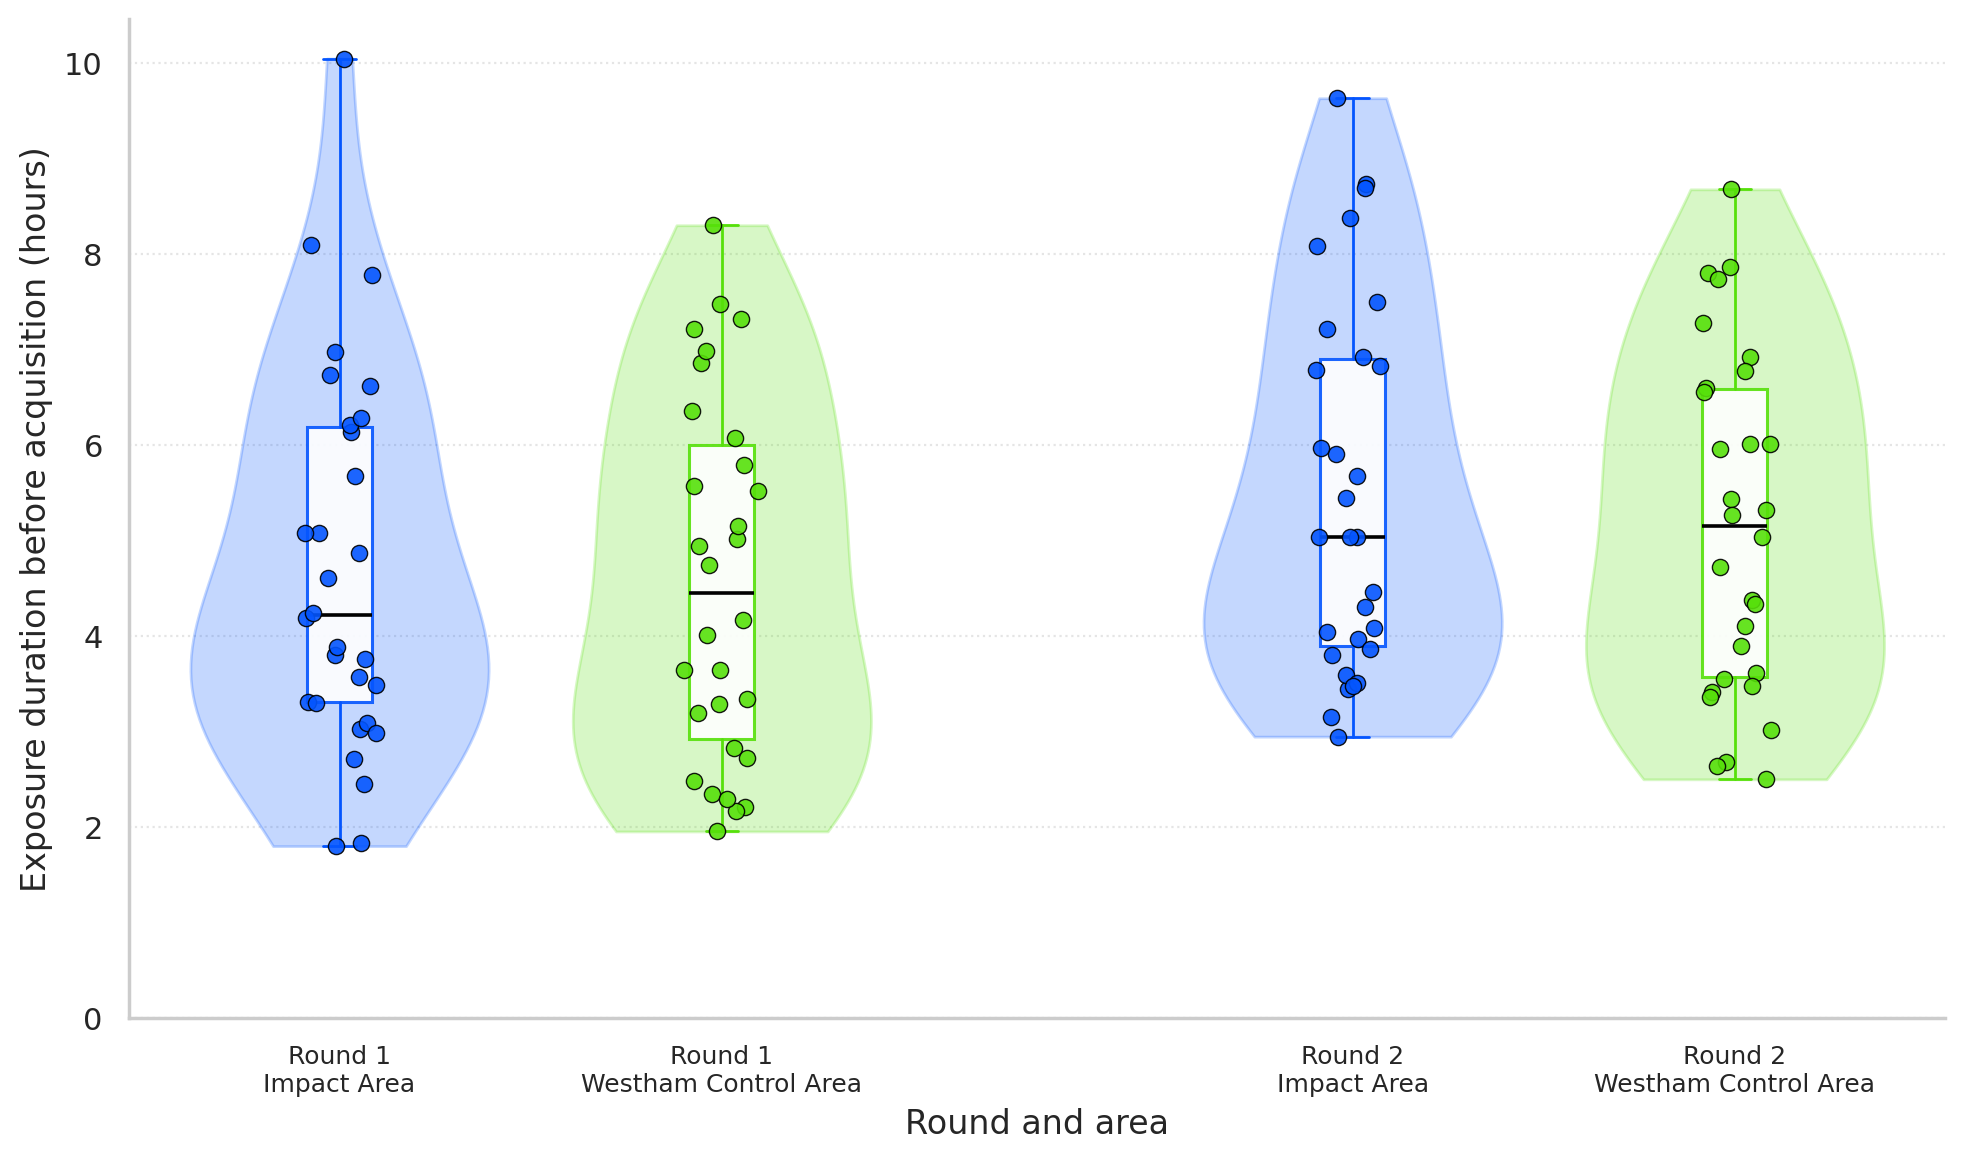

In [31]:
fig, ax, plot_df = plot_grouped_distribution(
    dataframe=df_times,
    value_column="emergence_acquisition_time_difference_hours",
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    group_by="round",
    ylabel="Exposure duration before acquisition (hours)",
    y_min=0,
    figsize=(10, 6),
)

plt.show()


In [51]:
stats = ["count", "min", "mean", "max"]
df_in_stats = df_times["emergence_acquisition_time_difference_hours"]

# Each site and round
stats_site_round = df_in_stats.groupby(level=["site", "round"]).agg(stats)


# All sites and all rounds combined
stats_all = df_in_stats.agg(stats).to_frame().T

stats_all.index = pd.MultiIndex.from_tuples(
    [("all", "all")],
    names=["site", "round"],
)

# Combine all summaries
df_stats = pd.concat(
    [
        stats_site_round,
        stats_all,
    ]
)

# display_for_word(df_stats.reset_index(), precision=3, show_index=False)

# Convert to hours and minutes (rounded), for columns except count in HH:MM format
df_stats[df_stats.columns.difference(["count"])] = df_stats[
    df_stats.columns.difference(["count"])
].applymap(lambda x: f"{int(x):02}:{int((x % 1) * 60):02}" if pd.notnull(x) else x)
display_for_word(df_stats.reset_index(), precision=3, show_index=False)

# display_for_word(df_stats[stats[1:]], precision=3, show_index=False)


/tmp/ipykernel_697/2595412274.py:29: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  ].applymap(lambda x: f"{int(x):02}:{int((x % 1) * 60):02}" if pd.notnull(x) else x)


site,round,count,min,mean,max
brunswick,1,30.000,01:47,04:43,10:02
brunswick,2,30.000,02:56,05:30,09:37
westham,1,30.000,01:57,04:35,08:17
westham,2,30.000,02:29,05:09,08:40
all,all,120.000,01:47,04:59,10:02


# PAR-related

In [52]:
df_par = read_df_from_csv(config.CONTAINER_FILE_PATHS['raw_par_data_csv'])

In [53]:
def calculate_accumulated_par(row):
    site, round_number, station_id = row.name

    acquisition_date = pd.to_datetime(row["date"]).strftime("%Y-%m-%d")
    par_station = f"PAR {site.title()}"

    daily_par = df_par.loc[
        (df_par["station"] == par_station) & (df_par["sample_day"] == acquisition_date)
    ].copy()

    times = pd.to_datetime(daily_par["date_time_parsed"])

    decimal_hours = times.dt.hour + times.dt.minute / 60 + times.dt.second / 3600

    # np.interp requires times to be ordered
    order = np.argsort(decimal_hours)
    decimal_hours = decimal_hours.iloc[order]
    accumulated_par = daily_par["Acc_PAR_mol_m²"].iloc[order]

    par_at_times = np.interp(
        [
            row["emergence_time_hours"],
            row["acquisition_time_hours"],
        ],
        decimal_hours,
        accumulated_par,
    )

    return par_at_times[1] - par_at_times[0]


df_contextual_data = df_times.copy()

df_contextual_data["accumulated_par_since_emergence_molperm2"] = (
    df_contextual_data.apply(calculate_accumulated_par, axis=1)
)


In [54]:
display(df_contextual_data.head())

date  \
site      round station_id               
brunswick 1     B1          2026-05-03   
                B10         2026-05-01   
                B11         2026-05-01   
                B12         2026-05-01   
                B13         2026-05-01   

                                                          geometry  elevation  \
site      round station_id                                                      
brunswick 1     B1           POINT Z (488833.82 5434224.912 0.875)    3.46975   
                B10         POINT Z (488875.848 5433865.401 0.616)    3.37800   
                B11         POINT Z (489056.793 5433627.776 0.376)    3.20575   
                B12          POINT Z (488897.659 5433305.857 0.33)    3.04725   
                B13         POINT Z (488555.946 5433166.387 0.133)    2.85350   

                                        low_tide_time  low_tide_level  \
site      round station_id                                              
brunswick 1     B1          2026-05-03T13:10:00-07:00           0.862   
                B10         2026-05-01T12:11:00-07:00           1.053   
                B11         2026-05-01T12:11:00-07:00           1.053   
                B12         2026-05-01T12:11:00-07:00           1.053   
                B13         2026-05-01T12:11:00-07:00           1.053   

                                       emergence_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T07:28:43-07:00   
                B10         2026-05-01T07:07:45-07:00   
                B11         2026-05-01T07:28:48-07:00   
                B12         2026-05-01T07:46:45-07:00   
                B13         2026-05-01T08:07:33-07:00   

                                     submergence_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T18:23:52-07:00   
                B10         2026-05-01T17:06:07-07:00   
                B11         2026-05-01T16:48:04-07:00   
                B12         2026-05-01T16:32:26-07:00   
                B13         2026-05-01T16:13:57-07:00   

                            exposure_duration_hours status  \
site      round station_id                                   
brunswick 1     B1                        10.919213     ok   
                B10                        9.972685     ok   
                B11                        9.321157     ok   
                B12                        8.761250     ok   
                B13                        8.106742     ok   

                                     acquisition_time  \
site      round station_id                              
brunswick 1     B1          2026-05-03T10:30:20-07:00   
                B10         2026-05-01T14:05:55-07:00   
                B11         2026-05-01T10:34:02-07:00   
                B12         2026-05-01T13:26:58-07:00   
                B13         2026-05-01T11:25:54-07:00   

                           emergence_acquisition_time_difference  \
site      round station_id                                         
brunswick 1     B1                         P0DT3H1M37.149275336S   
                B10                        P0DT6H58M9.700157357S   
                B11                        P0DT3H5M13.316590501S   
                B12                       P0DT5H40M12.650216295S   
                B13                       P0DT3H18M20.949336115S   

                            low_tide_time_hours  emergence_time_hours  \
site      round station_id                                              
brunswick 1     B1                    13.166667              7.478333   
                B10                   12.183333              7.128889   
                B11                   12.183333              7.480000   
                B12                   12.183333              7.778889   
                B13                   12.183333              8.125833   

                            submerg

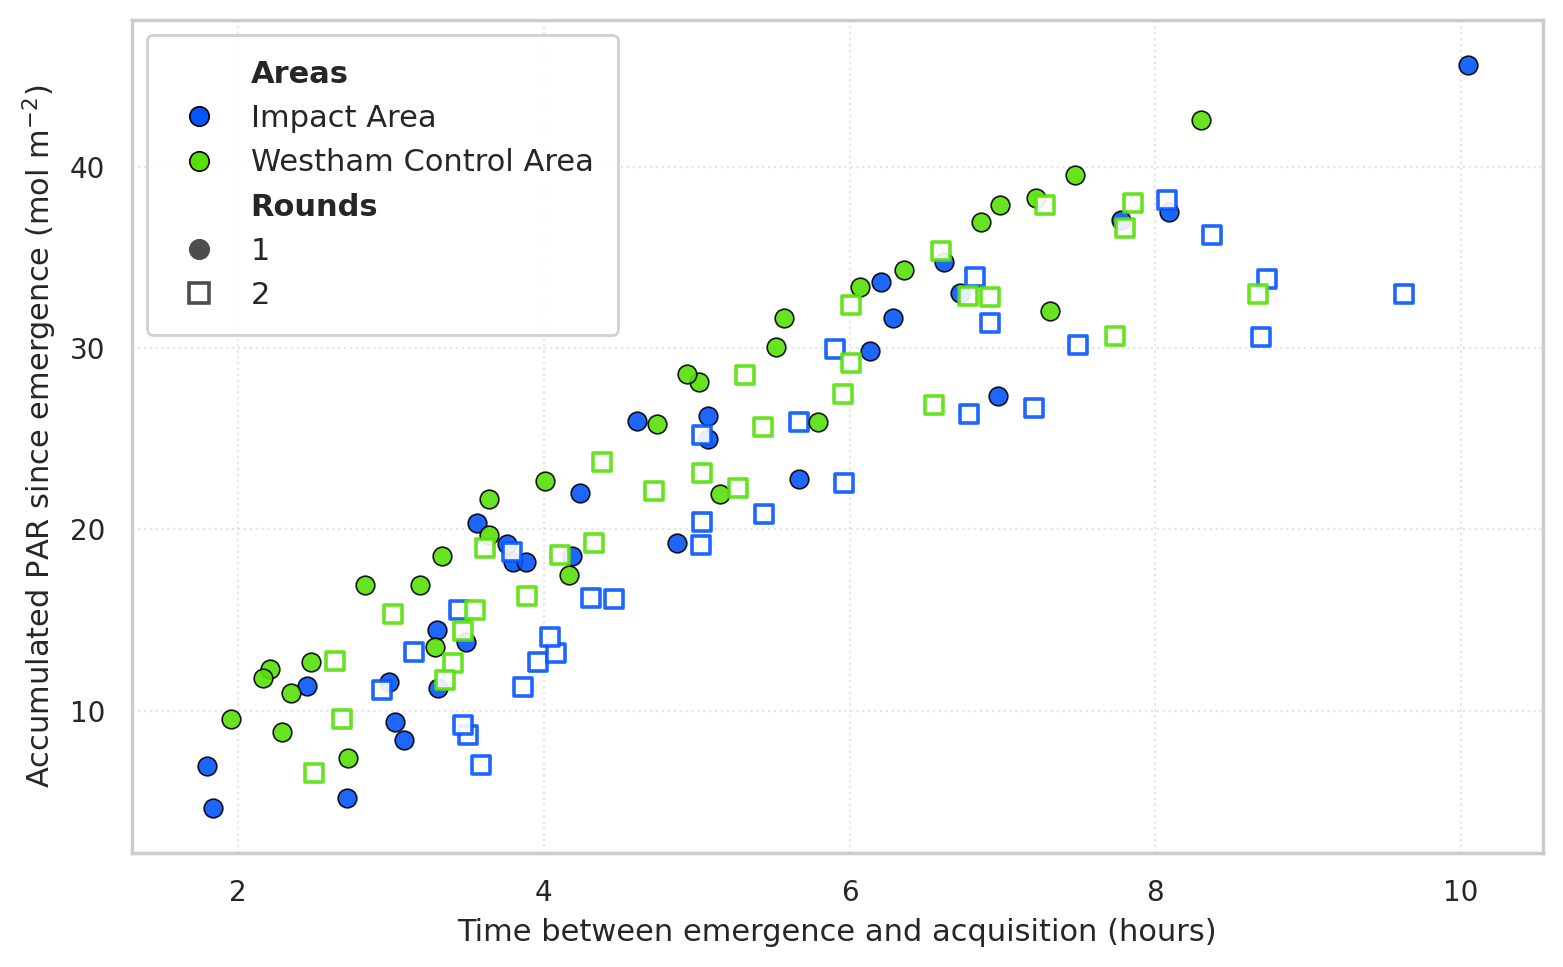

In [63]:
fig, ax = plot_contextual_scatter(
    dataframe=df_contextual_data,
    x_column="emergence_acquisition_time_difference_hours",
    y_column="accumulated_par_since_emergence_molperm2",
    site_colors=config.SITE_COLORS,
    site_labels=config.SITE_LABELS,
    xlabel="Time between emergence and acquisition (hours)",
    ylabel=(
        "Accumulated PAR since emergence "
        r"(mol m$^{-2}$)"
    ),
    add_one_to_one=False,
    figsize=(8, 5),
    legend_loc="best",
)

plt.show()


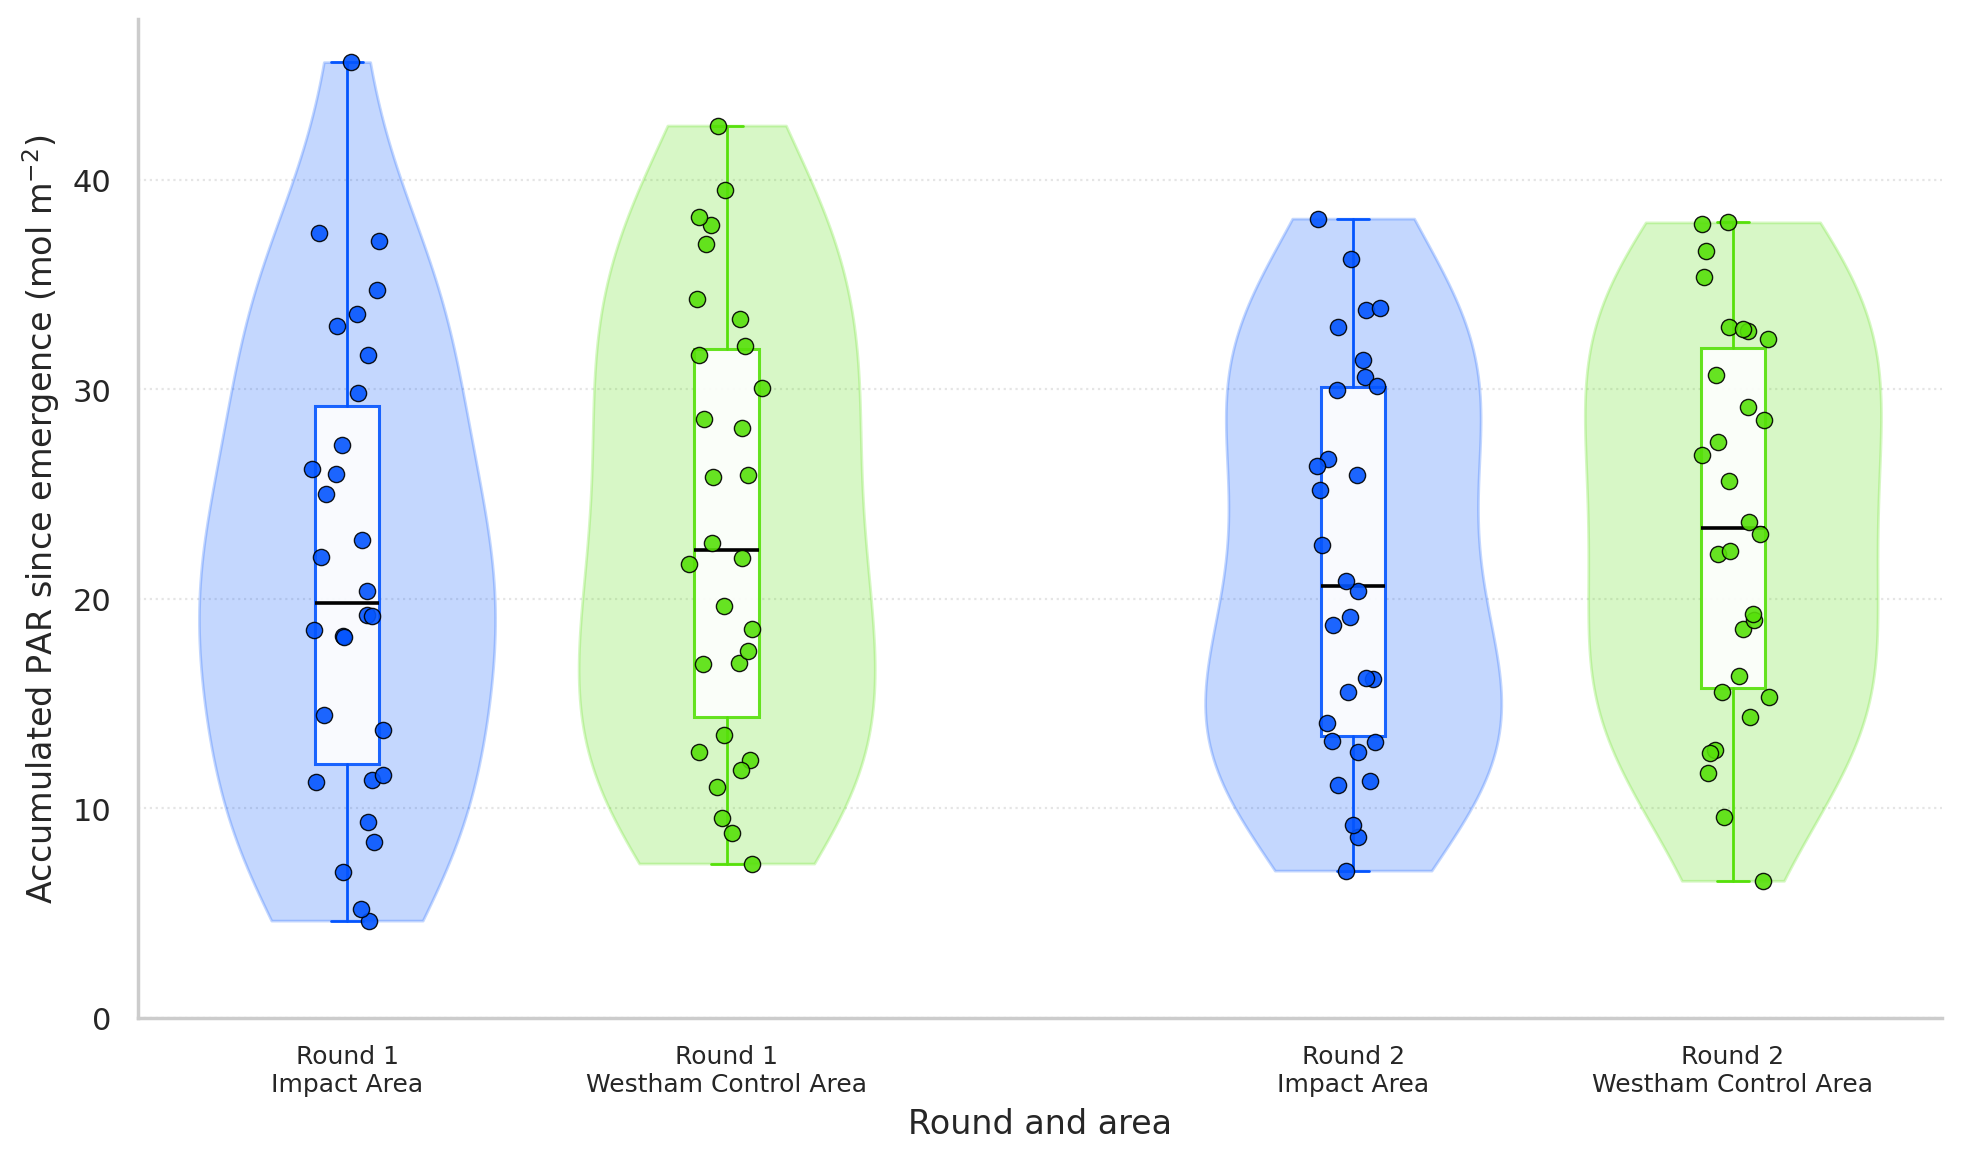

In [62]:
fig, ax, plot_df = plot_grouped_distribution(
    dataframe=df_contextual_data,
    value_column="accumulated_par_since_emergence_molperm2",
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    group_by="round",
    ylabel="Accumulated PAR since emergence (mol m$^{-2}$)",
    y_min=0,
    figsize=(10, 6),
)

plt.show()


In [65]:
stats = ["count", "min", "mean", "max"]
df_in_stats = df_contextual_data["accumulated_par_since_emergence_molperm2"]

# Each site and round
stats_site_round = df_in_stats.groupby(level=["site", "round"]).agg(stats)


# All sites and all rounds combined
stats_all = df_in_stats.agg(stats).to_frame().T

stats_all.index = pd.MultiIndex.from_tuples(
    [("all", "all")],
    names=["site", "round"],
)

# Combine all summaries
df_stats = pd.concat(
    [
        stats_site_round,
        stats_all,
    ]
)

display_for_word(df_stats.reset_index(), precision=3, show_index=False)

display_for_word(df_stats[stats[1:]], precision=1, show_index=False)


site,round,count,min,mean,max
brunswick,1,30.000,4.636,21.434,45.627
brunswick,2,30.000,7.024,21.709,38.154
westham,1,30.000,7.361,23.597,42.598
westham,2,30.000,6.538,23.666,37.975
all,all,120.000,4.636,22.601,45.627


min,mean,max
4.6,21.4,45.6
7.0,21.7,38.2
7.4,23.6,42.6
6.5,23.7,38.0
4.6,22.6,45.6


# Save Contextual Data

In [28]:
write_geojson(
    df_contextual_data,
    config.CONTAINER_FILE_PATHS["contextual_data_geojson"],
    index=True,
)

# To read it back:
# read_geojson(config.CONTAINER_FILE_PATHS["contextual_data_geojson"]).set_index(["site", "round", "station_id"]).sort_index()

# load_contextual_data(
#     config.CONTAINER_FILE_PATHS[
#         "contextual_data_geojson"
#     ]
# )


'wesa-fup-restricted-027817p/data/processed/contextual/contextual_data.geojson'

# END